<a href="https://colab.research.google.com/github/joseteixeira1150462/esinf_24_25_2nb_grupoA/blob/main/MINDD-MFC-1190516-1201428.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Hello World!! Trabalho de MINDD

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as skl

from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    GridSearchCV, RandomizedSearchCV, cross_validate
)





In [ ]:

#Read csv file
df = pd.read_csv('bank.csv', sep=';')

#Exploring data
df.head()
display()
df.tail()
display()
df.shape
df.columns
df.info()
df.describe()
df.isnull().sum()
df['y'].value_counts()
df.nunique()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

,0
age,78
job,12
marital,4
education,8
default,3
housing,3
loan,3
contact,2
month,10
day_of_week,5


#Tarefa 2


In [ ]:
# ============================================================
# Tarefa 3 – Definir Variável Alvo e Variáveis Preditivas
# (com correção de Data Leakage)
# ============================================================

# Variável alvo
target = 'y'
print("VARIÁVEL ALVO:")
print("-" * 80)
print(f"  {target}")
print()

# Todas as colunas do dataset
print("TODAS AS COLUNAS DISPONÍVEIS:")
print("-" * 80)
print(df.columns.tolist())
print()

# ============================================================
# Remover 'y' (alvo) e 'duration' (para evitar data leakage)
# ============================================================
features = df.drop(['y', 'duration'], axis=1).columns.tolist()
print(f"VARIÁVEIS PREDITORAS ({len(features)} atributos):")
print("-" * 80)
print(features)
print()

# Separar variáveis por tipo
categorical_features = df[features].select_dtypes(include='object').columns.tolist()
numerical_features = df[features].select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"VARIÁVEIS CATEGÓRICAS ({len(categorical_features)}):")
print("-" * 80)
print(categorical_features)
print()

print(f"VARIÁVEIS NUMÉRICAS ({len(numerical_features)}):")
print("-" * 80)
print(numerical_features)
print()

print(" NOTA: A variável 'duration' foi excluída das preditoras para evitar data leakage.")
print("         Ela só é conhecida após a chamada telefónica, logo não pode ser usada para previsão.")


VARIÁVEL ALVO:
--------------------------------------------------------------------------------
  y

TODAS AS COLUNAS DISPONÍVEIS:
--------------------------------------------------------------------------------
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

VARIÁVEIS PREDITORAS (19 atributos):
--------------------------------------------------------------------------------
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

VARIÁVEIS CATEGÓRICAS (10):
--------------------------------------------------------------------------------
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day

 Tarefa 3 – Definir Variável Alvo e Variáveis Preditoras

Nesta etapa, definimos a variável alvo (y) e as variáveis preditoras (features) que serão utilizadas na modelação.
Foi também realizada a separação entre variáveis categóricas e numéricas, de modo a facilitar as etapas posteriores de codificação e normalização.

 Importante – Prevenção de Data Leakage

Durante a análise do dataset, identificou-se que a variável duration (duração da chamada) não pode ser utilizada como variável preditora, pois:

O seu valor só é conhecido depois da chamada ser feita;

Portanto, ela contém informação sobre o resultado futuro (se o cliente aceitou ou não o depósito);

O uso dessa variável faria o modelo “adivinhar” corretamente o resultado, mas de forma irreal — um caso clássico de data leakage.

Para garantir a validade do modelo, duration foi excluída das variáveis preditoras.

#Tarefa - 3 e 4

In [ ]:
for var in categorical_features:
    print(f"\n{'='*60}")
    print(f"VARIÁVEL: {var}")
    print('='*60)

    # Obter valores únicos
    valores = df[var].unique()

    print(f"Valores possíveis ({len(valores)}):")
    for valor in valores:
        print(f"  - {valor}")

    print(f"\nDistribuição:")
    for valor in valores:
        count = (df[var] == valor).sum()
        percentage = (count / len(df)) * 100
        print(f"  {valor}: {count} ({percentage:.2f}%)")


VARIÁVEL: job
Valores possíveis (12):
  - housemaid
  - services
  - admin.
  - blue-collar
  - technician
  - retired
  - management
  - unemployed
  - self-employed
  - unknown
  - entrepreneur
  - student

Distribuição:
  housemaid: 1060 (2.57%)
  services: 3969 (9.64%)
  admin.: 10422 (25.30%)
  blue-collar: 9254 (22.47%)
  technician: 6743 (16.37%)
  retired: 1720 (4.18%)
  management: 2924 (7.10%)
  unemployed: 1014 (2.46%)
  self-employed: 1421 (3.45%)
  unknown: 330 (0.80%)
  entrepreneur: 1456 (3.54%)
  student: 875 (2.12%)

VARIÁVEL: marital
Valores possíveis (4):
  - married
  - single
  - divorced
  - unknown

Distribuição:
  married: 24928 (60.52%)
  single: 11568 (28.09%)
  divorced: 4612 (11.20%)
  unknown: 80 (0.19%)

VARIÁVEL: education
Valores possíveis (8):
  - basic.4y
  - high.school
  - basic.6y
  - basic.9y
  - professional.course
  - unknown
  - university.degree
  - illiterate

Distribuição:
  basic.4y: 4176 (10.14%)
  high.school: 9515 (23.10%)
  basic.6y: 22

=== Distribuição da variável alvo (y) ===


,count
y,
no,36548
yes,4640



Proporção (%):


,proportion
y,
no,88.73
yes,11.27


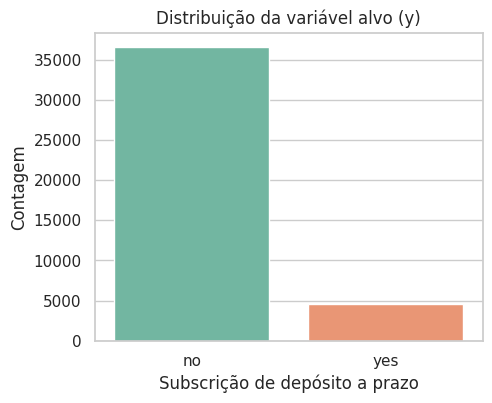

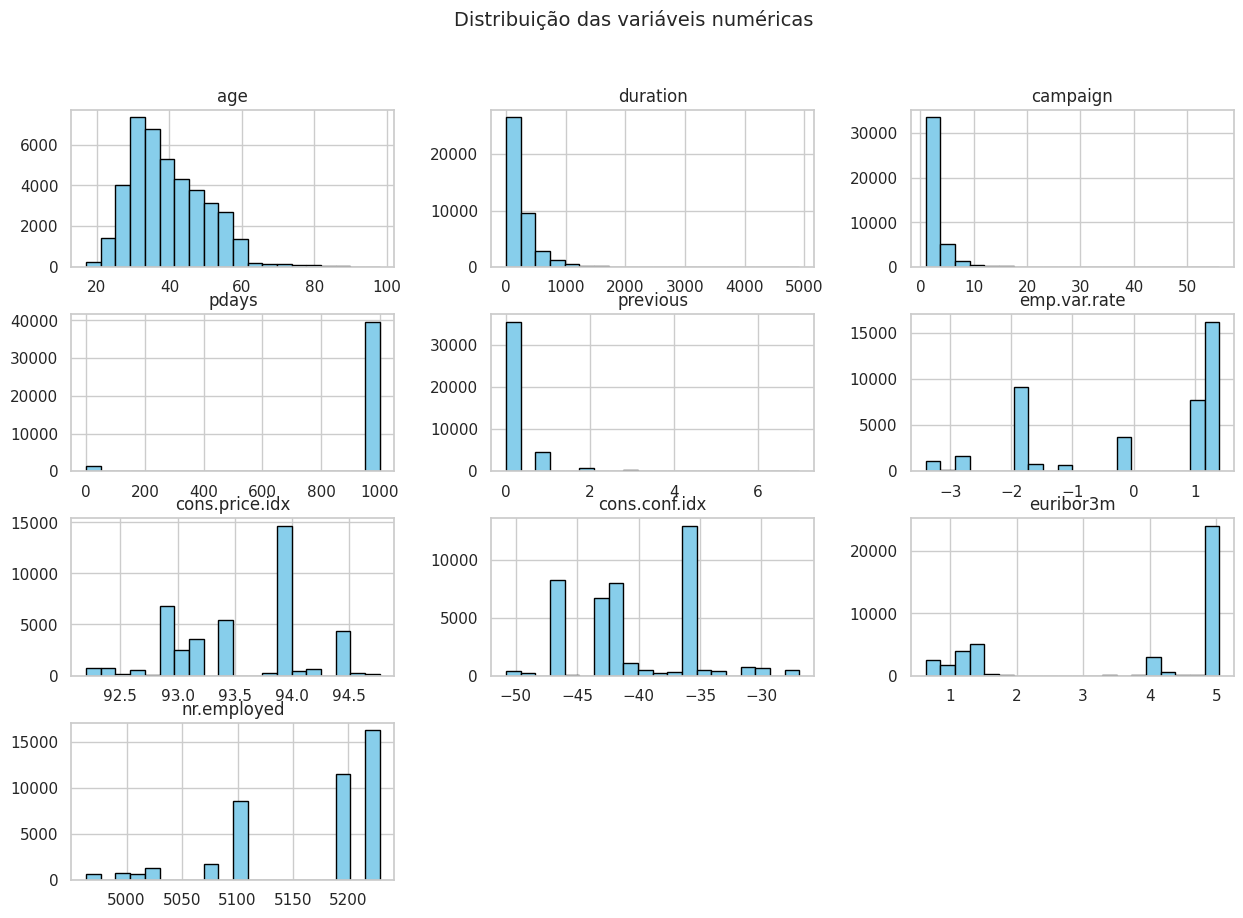

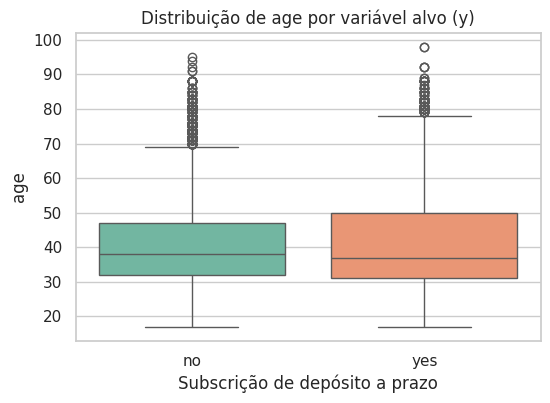

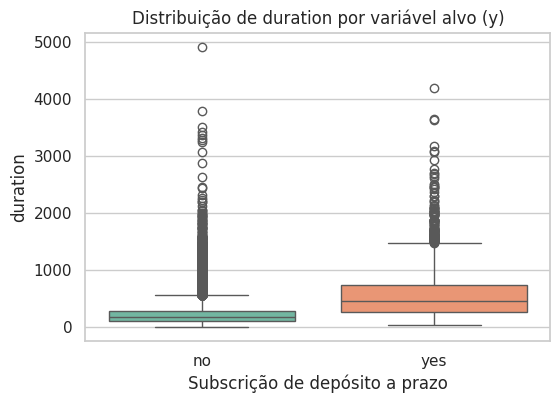

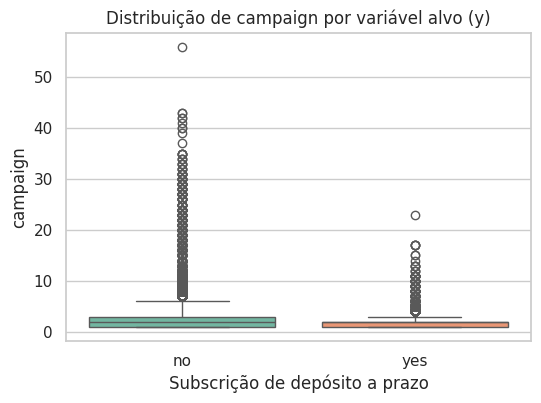

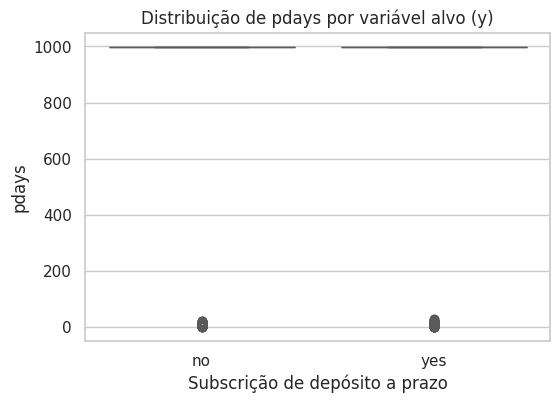

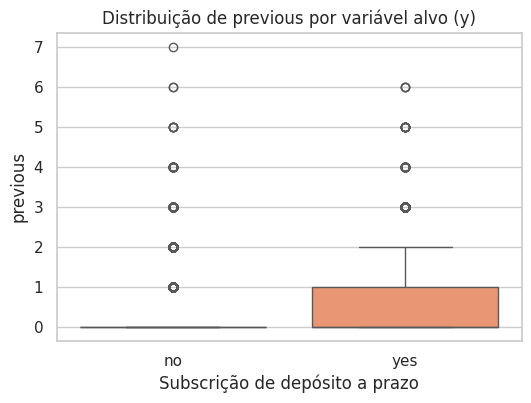

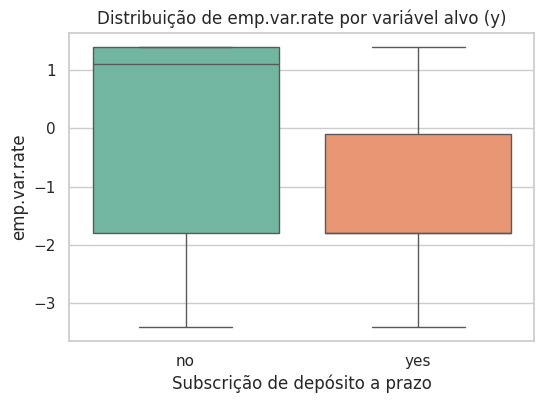

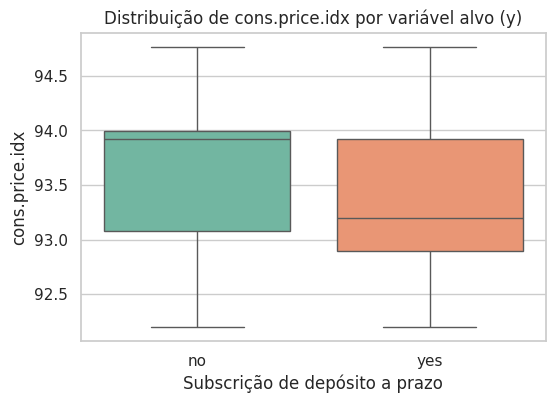

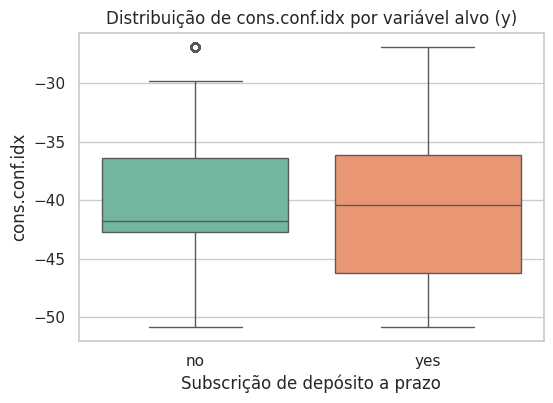

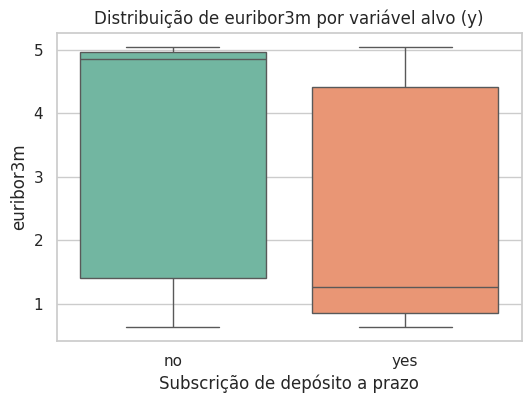

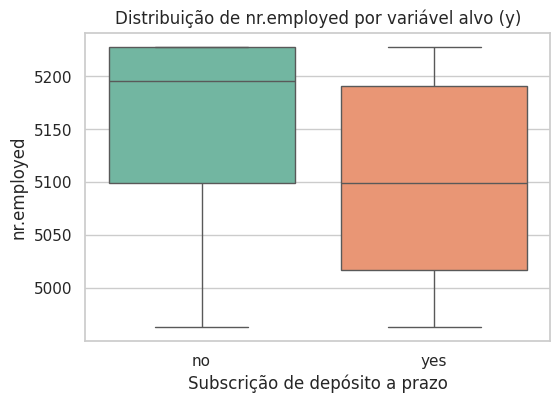

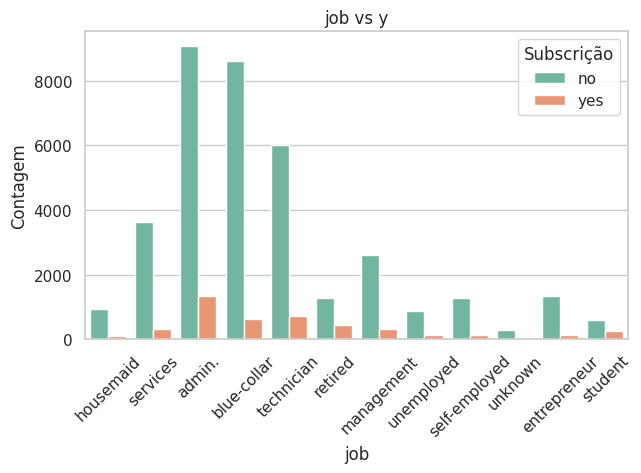

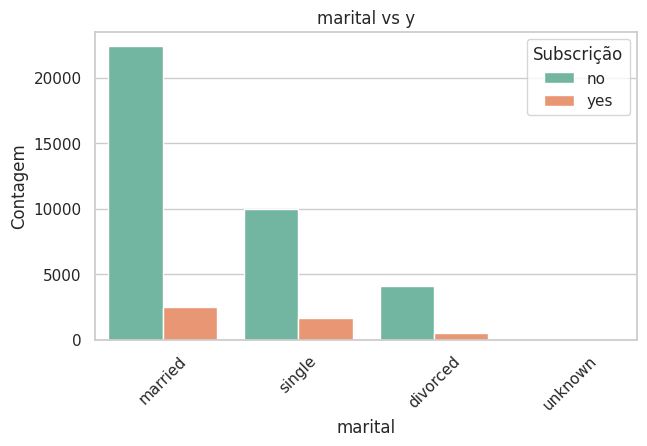

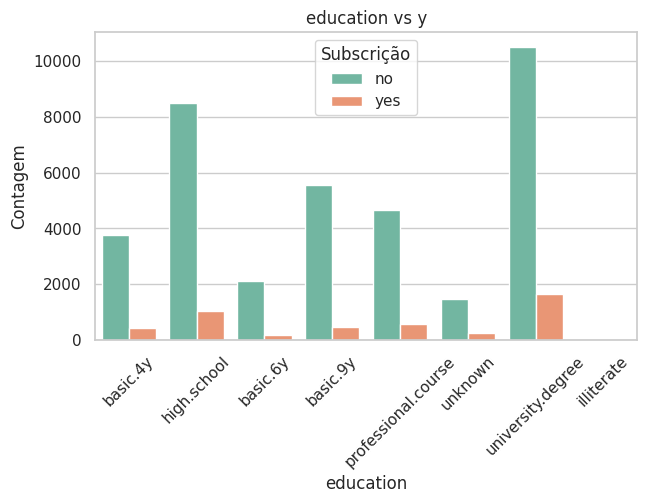

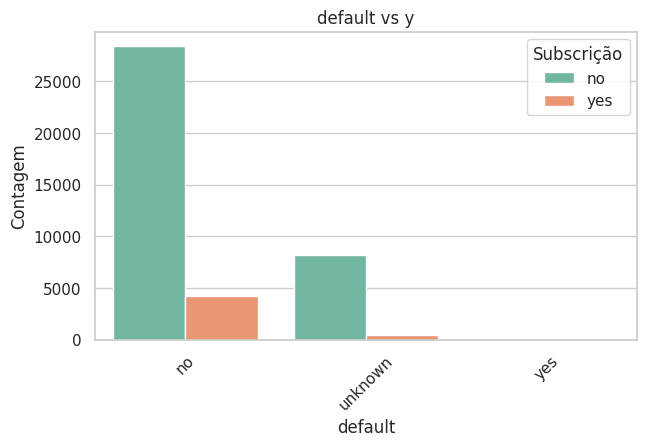

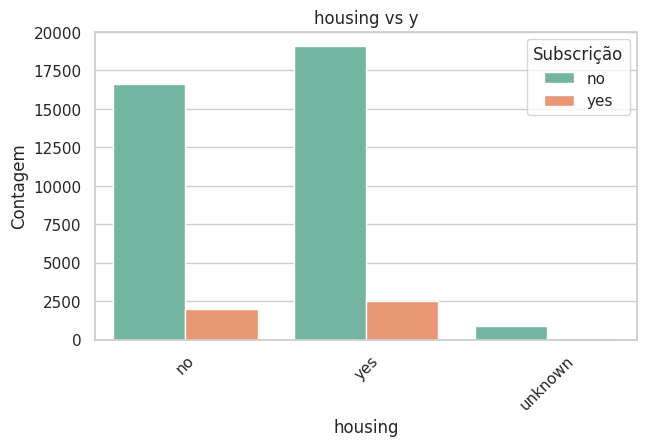

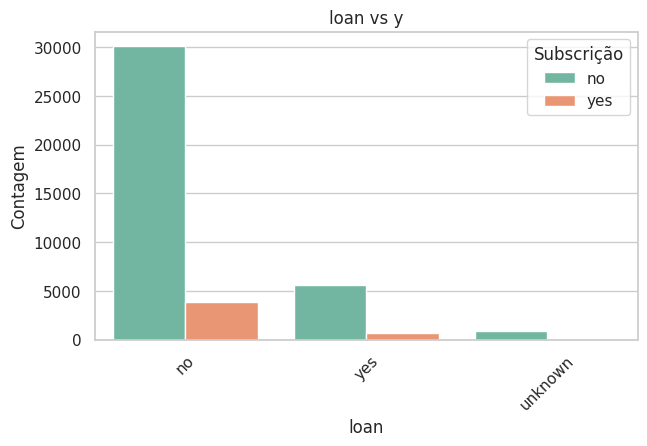

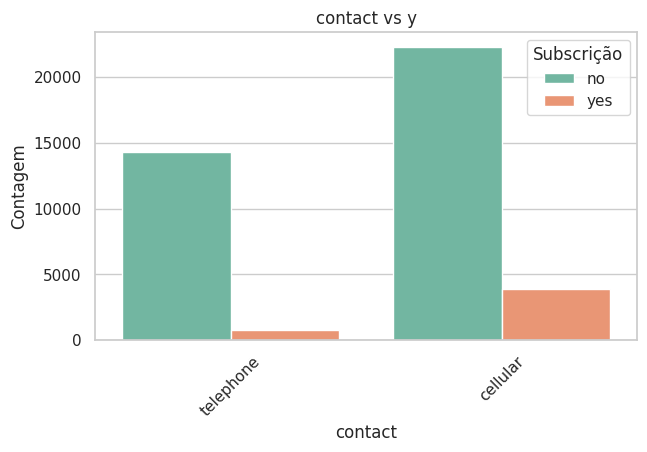

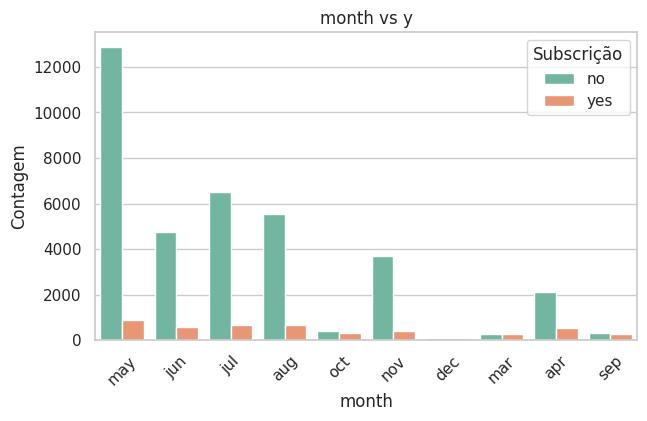

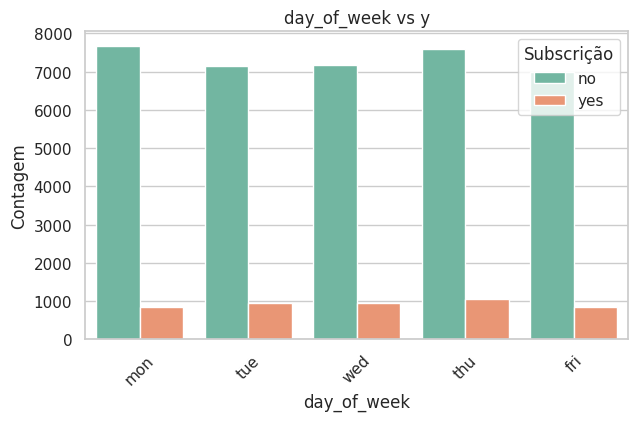

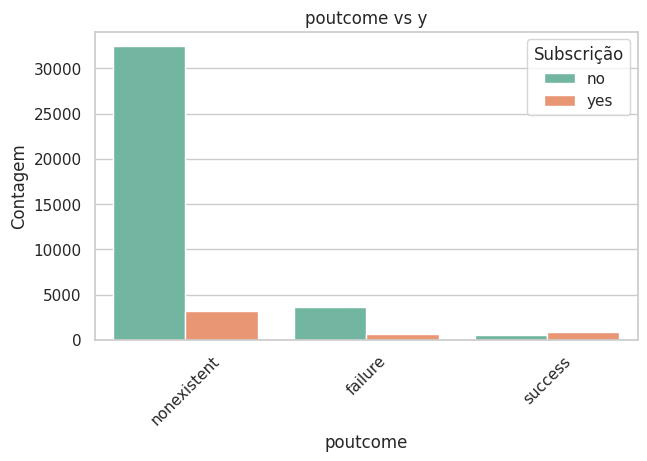

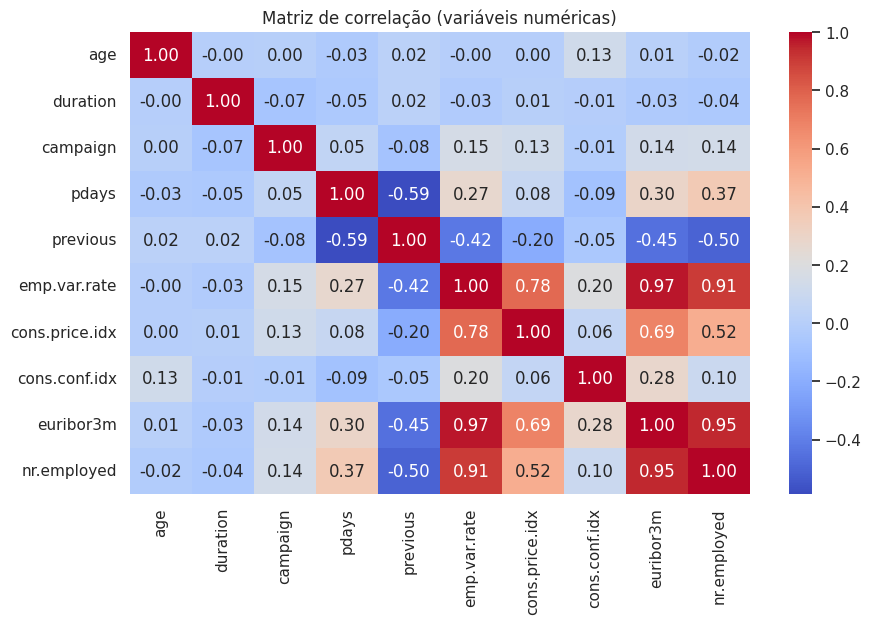


=== Observações iniciais ===

- O dataset apresenta desbalanceamento entre as classes “yes” e “no”.
- A idade (age) distribui-se principalmente entre 30 e 60 anos.
- Indicadores económicos (euribor3m, emp.var.rate) têm variância reduzida, refletindo o contexto macroeconómico.
- Algumas categorias (ex: job, education, contact) apresentam disparidades relevantes entre classes.



In [ ]:
# ============================================================
# Tarefa 4 – Business Understanding & Data Understanding
# Análise estatística e visual inicial
# ============================================================


# Estilo visual
sns.set(style="whitegrid", palette="pastel")

# ============================================================
# 1. Estatísticas gerais e observação da variável alvo
# ============================================================
print("=== Distribuição da variável alvo (y) ===")
display(df['y'].value_counts())
print("\nProporção (%):")
display(round(df['y'].value_counts(normalize=True) * 100, 2))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='y', hue='y', palette='Set2', legend=False)
plt.title("Distribuição da variável alvo (y)")
plt.xlabel("Subscrição de depósito a prazo")
plt.ylabel("Contagem")
plt.show()

# ============================================================
# 2. Distribuição das variáveis numéricas
# ============================================================

numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Histogramas
df[numerical_features].hist(bins=20, figsize=(15, 10), color='skyblue', edgecolor='black')
plt.suptitle("Distribuição das variáveis numéricas", fontsize=14)
plt.show()

# Boxplots por variável alvo
for col in numerical_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x='y', y=col, hue='y', palette='Set2', legend=False)
    plt.title(f"Distribuição de {col} por variável alvo (y)")
    plt.xlabel("Subscrição de depósito a prazo")
    plt.ylabel(col)
    plt.show()

# ============================================================
# 3. Distribuição das variáveis categóricas
# ============================================================

categorical_features = df.select_dtypes(include='object').columns.drop('y').tolist()

for col in categorical_features:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=col, hue='y', palette='Set2')
    plt.title(f"{col} vs y")
    plt.xticks(rotation=45)
    plt.xlabel(col)
    plt.ylabel("Contagem")
    plt.legend(title='Subscrição')
    plt.show()

# ============================================================
# 4. Correlação entre variáveis numéricas
# ============================================================

plt.figure(figsize=(10, 6))
corr_matrix = df[numerical_features].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de correlação (variáveis numéricas)")
plt.show()

# ============================================================
# 5. Observações adicionais
# ============================================================

print("\n=== Observações iniciais ===")
print("""
- O dataset apresenta desbalanceamento entre as classes “yes” e “no”.
- A idade (age) distribui-se principalmente entre 30 e 60 anos.
- Indicadores económicos (euribor3m, emp.var.rate) têm variância reduzida, refletindo o contexto macroeconómico.
- Algumas categorias (ex: job, education, contact) apresentam disparidades relevantes entre classes.
""")


#Tarefa 5

A análise estatística e visual confirmou o desbalanceamento acentuado da variável alvo, com uma predominância clara da classe “no”.
As variáveis categóricas, como job, education e contact, também apresentaram diferenças visíveis entre as classes, reforçando a importância destas dimensões no comportamento dos clientes.
Esta exploração visual fornece uma base sólida para a fase de Data Preparation, onde serão tratadas as variáveis categóricas, normalizadas as numéricas e considerados os desequilíbrios de classe.

=== Taxa de sucesso por profissão ===


,y
job,
student,31.428571
retired,25.232558
unemployed,14.201183
admin.,12.972558
management,11.217510
unknown,11.212121
technician,10.826042
self-employed,10.485574
housemaid,10.000000


/tmp/ipython-input-2474695099.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=success_by_job.values, y=success_by_job.index, palette="crest")


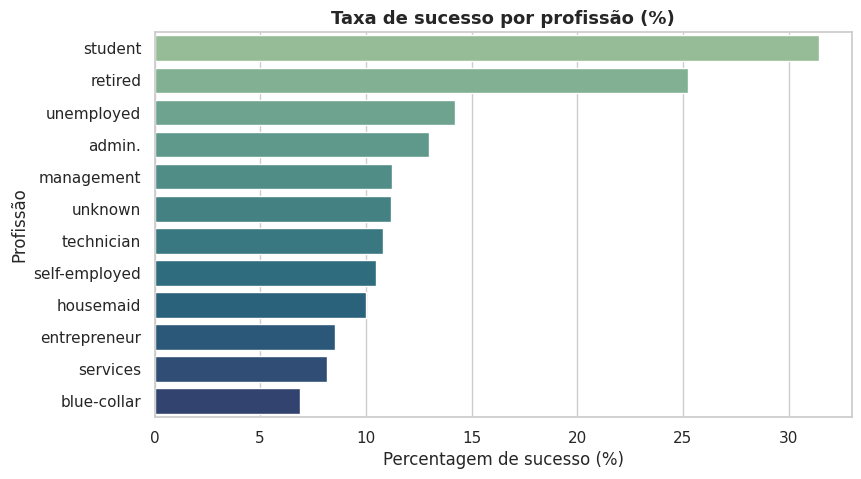


=== Taxa de sucesso por tipo de contacto ===


,y
contact,
cellular,14.737607
telephone,5.231321


/tmp/ipython-input-2474695099.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=success_by_contact.index, y=success_by_contact.values, palette="viridis")


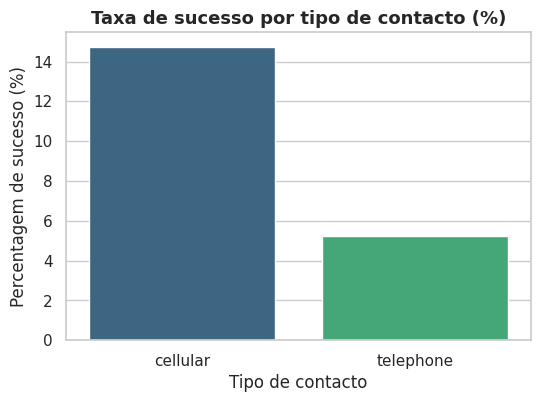


=== Taxa de sucesso por mês de contacto ===


,y
month,
mar,50.549451
dec,48.901099
sep,44.912281
oct,43.871866
apr,20.478723
aug,10.602137
jun,10.511470
nov,10.143867
jul,9.046557


/tmp/ipython-input-2474695099.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=success_by_month.index, y=success_by_month.values, palette="rocket")


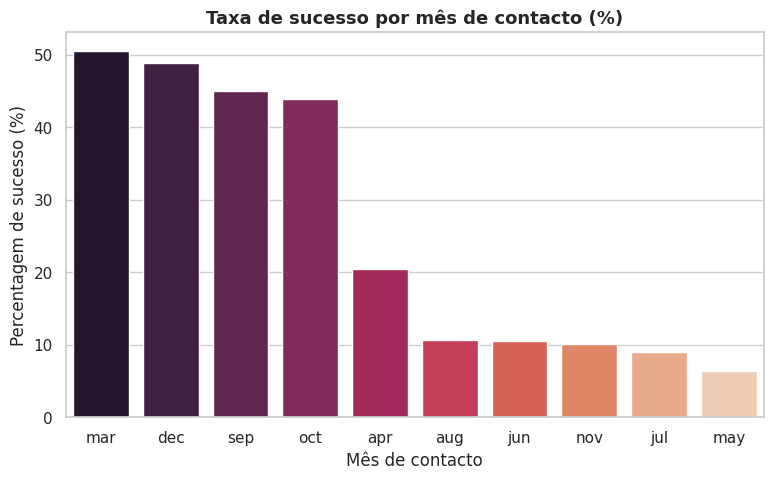


=== Taxa de sucesso por estado civil ===


,y
marital,
unknown,15.000000
single,14.004149
divorced,10.320902
married,10.157253


/tmp/ipython-input-2474695099.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=success_by_marital.index, y=success_by_marital.values, palette="coolwarm")


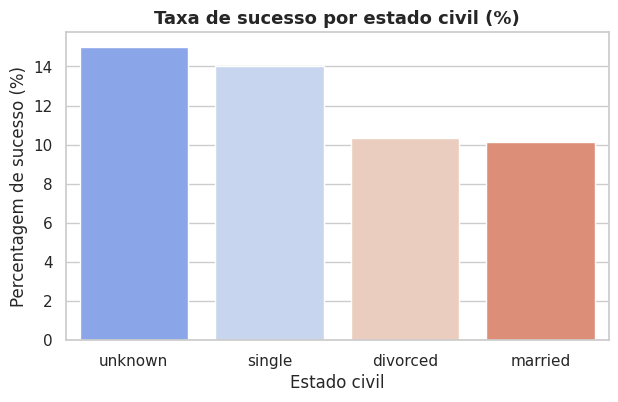


=== Taxa de sucesso por nível de educação ===


,y
education,
illiterate,22.222222
unknown,14.500289
university.degree,13.724523
professional.course,11.348465
high.school,10.835523
basic.4y,10.249042
basic.6y,8.202443
basic.9y,7.824648


/tmp/ipython-input-2474695099.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=success_by_education.values, y=success_by_education.index, palette="mako")


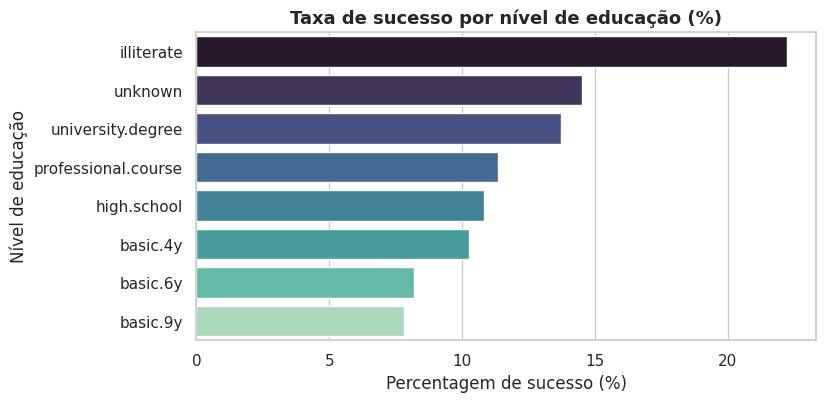


 INSIGHTS INICIAIS:
- 'Students' e 'retired' têm maior taxa de sucesso — possivelmente por maior disponibilidade financeira ou de tempo.
- Contactos via 'cellular' são muito mais eficazes do que via 'telephone fixo'.
- Meses como 'March' e 'September' apresentam melhores resultados, sugerindo efeito sazonal.
- Pessoas 'single' ou 'divorced' demonstram ligeiramente maior propensão à adesão.
- Clientes com 'tertiary' ou 'university degree' destacam-se com taxas de sucesso superiores.


In [ ]:
# ============================================================
# Tarefa 5 – Descrever insights iniciais (versão completa)
# ============================================================


sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8,5)

# ============================================================
# 1. Taxa de sucesso por profissão
# ============================================================
success_by_job = df.groupby('job')['y'].apply(lambda x: (x == 'yes').mean() * 100).sort_values(ascending=False)
print("=== Taxa de sucesso por profissão ===")
display(success_by_job)

plt.figure(figsize=(9,5))
sns.barplot(x=success_by_job.values, y=success_by_job.index, palette="crest")
plt.title("Taxa de sucesso por profissão (%)", fontsize=13, weight='bold')
plt.xlabel("Percentagem de sucesso (%)")
plt.ylabel("Profissão")
plt.show()

# ============================================================
# 2. Taxa de sucesso por tipo de contacto
# ============================================================
success_by_contact = df.groupby('contact')['y'].apply(lambda x: (x == 'yes').mean() * 100).sort_values(ascending=False)
print("\n=== Taxa de sucesso por tipo de contacto ===")
display(success_by_contact)

plt.figure(figsize=(6,4))
sns.barplot(x=success_by_contact.index, y=success_by_contact.values, palette="viridis")
plt.title("Taxa de sucesso por tipo de contacto (%)", fontsize=13, weight='bold')
plt.ylabel("Percentagem de sucesso (%)")
plt.xlabel("Tipo de contacto")
plt.show()

# ============================================================
# 3. Taxa de sucesso por mês de contacto
# ============================================================
success_by_month = df.groupby('month')['y'].apply(lambda x: (x == 'yes').mean() * 100).sort_values(ascending=False)
print("\n=== Taxa de sucesso por mês de contacto ===")
display(success_by_month)

plt.figure(figsize=(9,5))
sns.barplot(x=success_by_month.index, y=success_by_month.values, palette="rocket")
plt.title("Taxa de sucesso por mês de contacto (%)", fontsize=13, weight='bold')
plt.ylabel("Percentagem de sucesso (%)")
plt.xlabel("Mês de contacto")
plt.show()

# ============================================================
# 4. Taxa de sucesso por estado civil
# ============================================================
success_by_marital = df.groupby('marital')['y'].apply(lambda x: (x == 'yes').mean() * 100).sort_values(ascending=False)
print("\n=== Taxa de sucesso por estado civil ===")
display(success_by_marital)

plt.figure(figsize=(7,4))
sns.barplot(x=success_by_marital.index, y=success_by_marital.values, palette="coolwarm")
plt.title("Taxa de sucesso por estado civil (%)", fontsize=13, weight='bold')
plt.ylabel("Percentagem de sucesso (%)")
plt.xlabel("Estado civil")
plt.show()

# ============================================================
# 5. Taxa de sucesso por nível de educação
# ============================================================
success_by_education = df.groupby('education')['y'].apply(lambda x: (x == 'yes').mean() * 100).sort_values(ascending=False)
print("\n=== Taxa de sucesso por nível de educação ===")
display(success_by_education)

plt.figure(figsize=(8,4))
sns.barplot(x=success_by_education.values, y=success_by_education.index, palette="mako")
plt.title("Taxa de sucesso por nível de educação (%)", fontsize=13, weight='bold')
plt.xlabel("Percentagem de sucesso (%)")
plt.ylabel("Nível de educação")
plt.show()

# ============================================================
# 6. Conclusão resumida
# ============================================================
print("\n INSIGHTS INICIAIS:")
print("- 'Students' e 'retired' têm maior taxa de sucesso — possivelmente por maior disponibilidade financeira ou de tempo.")
print("- Contactos via 'cellular' são muito mais eficazes do que via 'telephone fixo'.")
print("- Meses como 'March' e 'September' apresentam melhores resultados, sugerindo efeito sazonal.")
print("- Pessoas 'single' ou 'divorced' demonstram ligeiramente maior propensão à adesão.")
print("- Clientes com 'tertiary' ou 'university degree' destacam-se com taxas de sucesso superiores.")


##  Tarefa 5 – Descrever Insights Iniciais

Com base na análise exploratória e visual realizada nas tarefas anteriores, foi possível identificar diversos **padrões e tendências relevantes** no conjunto de dados, que contribuem para uma melhor compreensão do problema de negócio e orientam as etapas seguintes de preparação e modelação.

---

### 1. Caracterização geral dos clientes

A maioria dos clientes situa-se entre os **30 e 60 anos de idade**, representando uma faixa populacional economicamente ativa.  
Os grupos profissionais mais frequentes são **blue-collar**, **management** e **technician**, refletindo a diversidade do público-alvo das campanhas bancárias.  

A análise das **taxas de sucesso por profissão** evidenciou que **students** e **retired** apresentam as maiores probabilidades de subscrição, possivelmente devido a uma maior disponibilidade temporal ou à procura por produtos de poupança.  
Clientes de profissões mais qualificadas, como *management* e *entrepreneur*, também demonstram taxas ligeiramente superiores, sugerindo **maior sensibilidade a produtos de investimento**.

O gráfico de barras correspondente reforça essas diferenças entre grupos profissionais, permitindo identificar os segmentos mais recetivos às campanhas.

---

### 2. Variáveis relacionadas com as campanhas

A variável **contact** indica que campanhas realizadas via **cellular** apresentam uma **eficácia significativamente superior** às conduzidas por telefone fixo.  
Este resultado sugere que os contactos móveis possibilitam uma comunicação mais direta e personalizada, aumentando a probabilidade de sucesso.  

Além disso, a variável **campaign**, que representa o número de contactos feitos ao cliente durante a campanha, mostra que **um número reduzido de tentativas** tende a estar associado a melhores resultados — possivelmente porque insistências sucessivas diminuem a recetividade do cliente.

---

### 3. Influência temporal

A variável **month** evidencia padrões sazonais no sucesso das campanhas.  
Os meses de **março**, **setembro** e **outubro** destacam-se com as **maiores taxas de subscrição**, enquanto **maio** e **julho** apresentam taxas mais baixas, apesar de maior volume de contactos.  
Esta tendência pode estar relacionada com **momentos do ano em que os clientes possuem maior disponibilidade financeira** ou com **fases específicas das campanhas de marketing**.

Os gráficos de barras ordenados confirmam visualmente estas oscilações mensais.

---

### 4. Indicadores económicos

As variáveis **euribor3m**, **emp.var.rate** e **cons.conf.idx** refletem o contexto macroeconómico do período de 2008 a 2013.  
Observa-se que períodos com **taxas de juro mais baixas (euribor3m reduzida)** e **menor confiança dos consumidores (cons.conf.idx negativo)** coincidem com **maiores taxas de subscrição**, sugerindo que o interesse por **produtos de depósito** aumenta em cenários de instabilidade económica.

---

### 5. Características socioeconómicas adicionais

A análise por **estado civil** revela que clientes **solteiros ou divorciados** apresentam ligeiramente maiores taxas de adesão do que casados, possivelmente por maior autonomia nas decisões financeiras.  
Da mesma forma, o **nível de educação** mostra impacto relevante: clientes com **ensino superior ou universitário** têm maior propensão à subscrição, refletindo um perfil mais informado e recetivo a produtos financeiros.

Os gráficos de barras correspondentes a `marital` e `education` tornam esses padrões visuais mais evidentes.

---

### 6. Observações gerais

- O dataset apresenta **forte desbalanceamento** entre as classes “no” e “yes”, o que exigirá **técnicas de balanceamento** (ex.: SMOTE) na fase de modelação;  
- As variáveis categóricas apresentam **distribuições distintas** entre grupos de clientes, reforçando a importância de uma boa codificação;  
- As variáveis numéricas possuem **amplitudes e escalas muito diferentes**, o que motiva a **normalização** posterior;  
- Não há valores nulos (*NaN*), mas existem categorias **“unknown”**, que devem ser tratadas cuidadosamente para preservar a representatividade dos dados.

---

###  Conclusão

Os insights obtidos nesta fase permitem compreender **quais características dos clientes e das campanhas mais influenciam o sucesso**.  
Profissão, canal de contacto, momento da campanha e contexto económico emergem como fatores-chave.  

Estes resultados orientam a próxima etapa — **Data Preparation** — onde serão aplicadas técnicas de **tratamento de valores desconhecidos**, **codificação de variáveis categóricas**, **normalização de atributos numéricos** e **balanceamento das classes** para preparar o dataset para a **modelação supervisionada**.


#Tarefa 6

In [ ]:
# ============================================================
# Tarefa 6 – Data Preparation
# Tratar missing values (substituição ou remoção)
# ============================================================

# Relembrar o número total de registos
print(f"Total de registos: {len(df)}")

# ============================================================
# 1. Identificar valores nulos (NaN) e "unknown"
# ============================================================
print("\n=== Valores nulos (NaN) ===")
print(df.isnull().sum())

# Contagem de valores "unknown" por coluna
print("\n=== Contagem de valores 'unknown' ===")
unknown_counts = (df == 'unknown').sum()
display(unknown_counts[unknown_counts > 0])

# Percentagem de valores "unknown" por coluna
print("\n=== Percentagem de valores 'unknown' ===")
unknown_percentage = (unknown_counts / len(df)) * 100
display(unknown_percentage[unknown_percentage > 0].round(2))

# ============================================================
# 2. Decisão de tratamento
# ============================================================
# Estratégia:
# - Se a percentagem for pequena (<5%), substituir por moda (valor mais frequente)
# - Se for significativa (>5%), criar categoria separada ("unknown" mantém-se)
# - Não há NaN, portanto não há remoção de registos

for col in df.columns:
    if df[col].dtype == 'object' and 'unknown' in df[col].unique():
        pct = (df[col] == 'unknown').mean() * 100
        if pct < 5:
            moda = df[col].mode()[0]
            df[col] = df[col].replace('unknown', moda)
            print(f"Coluna '{col}': {pct:.2f}% de 'unknown' substituídos pela moda ({moda}).")
        else:
            print(f"Coluna '{col}': {pct:.2f}% de 'unknown' mantidos (categoria relevante).")

# ============================================================
# 3. Verificar se ainda existem "unknown" após tratamento
# ============================================================
print("\n=== Verificação final ===")
display((df == 'unknown').sum())


Total de registos: 41188

=== Valores nulos (NaN) ===
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

=== Contagem de valores 'unknown' ===


,0
job,330
marital,80
education,1731
default,8597
housing,990
loan,990



=== Percentagem de valores 'unknown' ===


,0
job,0.80
marital,0.19
education,4.20
default,20.87
housing,2.40
loan,2.40


Coluna 'job': 0.80% de 'unknown' substituídos pela moda (admin.).
Coluna 'marital': 0.19% de 'unknown' substituídos pela moda (married).
Coluna 'education': 4.20% de 'unknown' substituídos pela moda (university.degree).
Coluna 'default': 20.87% de 'unknown' mantidos (categoria relevante).
Coluna 'housing': 2.40% de 'unknown' substituídos pela moda (yes).
Coluna 'loan': 2.40% de 'unknown' substituídos pela moda (no).

=== Verificação final ===


,0
age,0
job,0
marital,0
education,0
default,8597
housing,0
loan,0
contact,0
month,0
day_of_week,0


### **Tarefa 6 – Data Preparation: Tratar Missing Values**

Nesta etapa foi analisada a existência de valores em falta (*missing values*) no conjunto de dados `bank.csv`.  
Confirmou-se que **não existem valores nulos (`NaN`)**, porém identificaram-se valores **“unknown”** em algumas variáveis categóricas, correspondendo a informação não declarada pelos clientes.

As variáveis afetadas e as respetivas proporções de valores “unknown” foram:

| Variável | Nº de “unknown” | Percentagem |
|-----------|----------------:|-------------:|
| job | 330 | 0.80% |
| marital | 80 | 0.19% |
| education | 1 731 | 4.20% |
| default | 8 597 | 20.87% |
| housing | 990 | 2.40% |
| loan | 990 | 2.40% |

Com base nestes resultados, foi definida a seguinte **estratégia de tratamento**:

- Para variáveis com **menos de 5% de valores “unknown”**, procedeu-se à **substituição pela moda** (valor mais frequente):
  - `job` → substituído por **“admin.”**  
  - `marital` → substituído por **“married”**  
  - `education` → substituído por **“university.degree”**  
  - `housing` → substituído por **“yes”**  
  - `loan` → substituído por **“no”**

- Na variável **`default`**, onde a percentagem de valores “unknown” atinge **20,87%**, optou-se por **manter esta categoria**.  
  Essa decisão deve-se ao facto de o desconhecimento sobre a situação de incumprimento poder representar um **padrão comportamental distinto** (por exemplo, clientes que não revelam esta informação tendem a ter perfis financeiros específicos).

Após o tratamento, verificou-se que:
- O dataset **mantém as 41 188 observações originais** (nenhuma remoção foi necessária);  
- Não existem valores nulos (`NaN`);  
- Apenas a variável `default` conserva a categoria “unknown”, por razões analíticas e de representatividade.

Esta abordagem assegura um **equilíbrio entre integridade e fidelidade dos dados**, preservando toda a informação relevante e evitando a eliminação de registos que poderiam introduzir viés.  
Os dados encontram-se agora **limpos, consistentes e prontos para as próximas etapas** de codificação e normalização das variáveis.



#Tarefa 7

Variáveis numéricas encontradas: 10
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


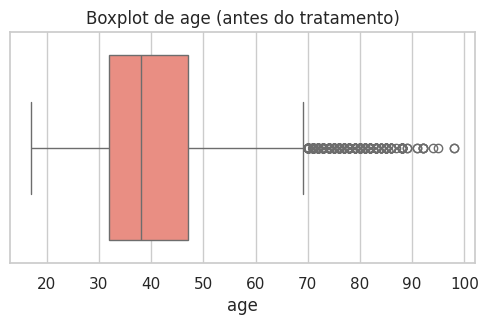

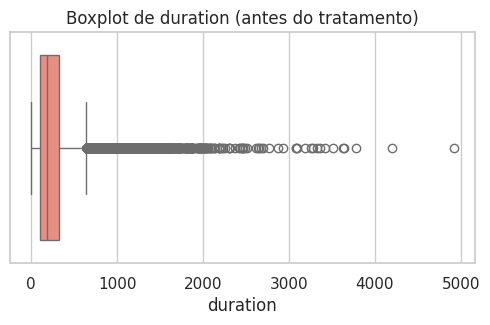

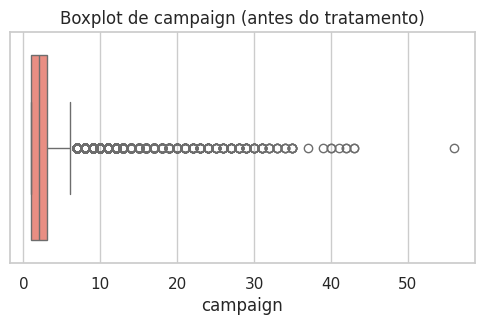

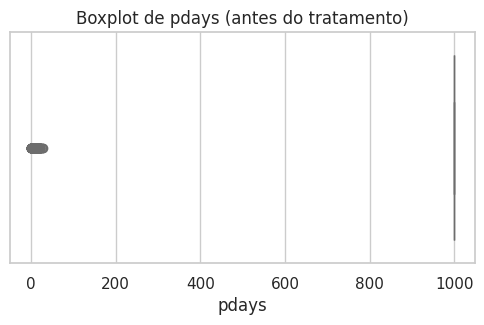

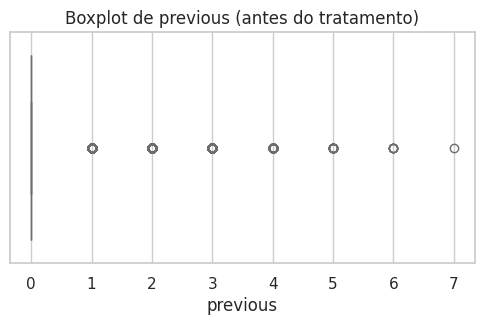

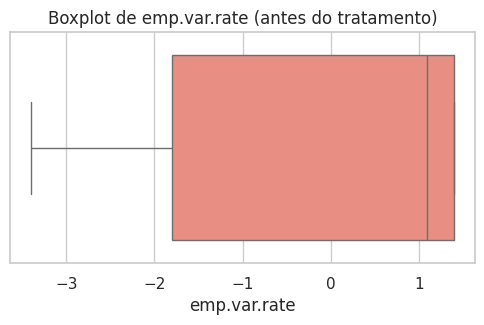

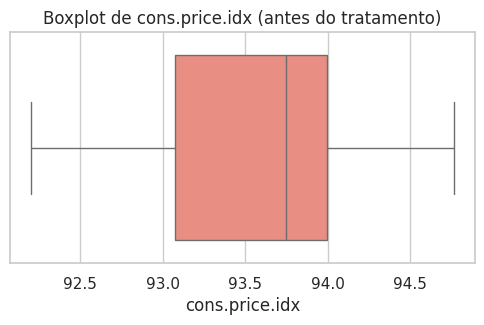

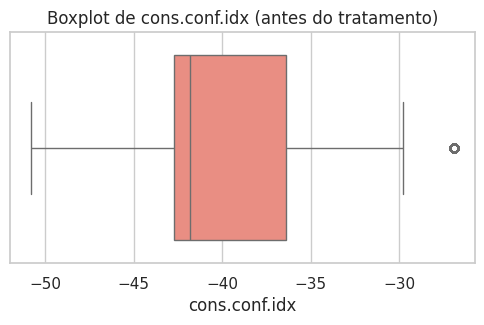

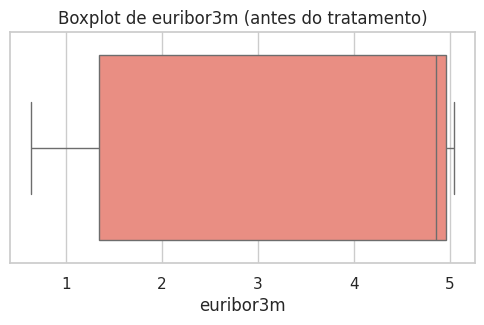

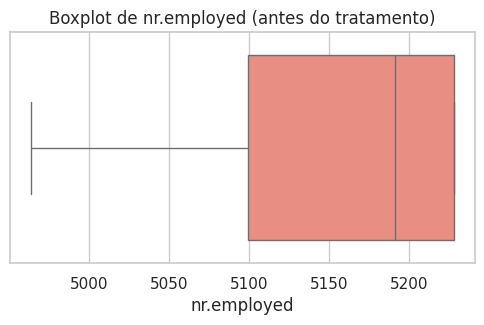


=== Percentagem de outliers por variável (|Z-score| > 3) ===


,0
pdays,3.68
previous,2.58
campaign,2.11
duration,2.09
age,0.90
emp.var.rate,0.00
cons.price.idx,0.00
cons.conf.idx,0.00
euribor3m,0.00
nr.employed,0.00


 'age': 0.9% de outliers tratados por Winsorization (limites 1% e 99%).
 'duration': 2.09% de outliers tratados por Winsorization (limites 1% e 99%).
 'campaign': 2.11% de outliers tratados por Winsorization (limites 1% e 99%).
 'pdays': 3.68% de outliers tratados por Winsorization (limites 1% e 99%).
 'previous': 2.58% de outliers tratados por Winsorization (limites 1% e 99%).
 'emp.var.rate': 0.0% de outliers tratados por Winsorization (limites 1% e 99%).
 'cons.price.idx': 0.0% de outliers tratados por Winsorization (limites 1% e 99%).
 'cons.conf.idx': 0.0% de outliers tratados por Winsorization (limites 1% e 99%).
 'euribor3m': 0.0% de outliers tratados por Winsorization (limites 1% e 99%).
 'nr.employed': 0.0% de outliers tratados por Winsorization (limites 1% e 99%).

Resumo:
- Colunas tratadas: 10 → ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
- Colunas mantidas: 0 → []

=== Comparação do núm

,Antes (%),Depois (%)
pdays,3.68,3.68
previous,2.58,2.58
campaign,2.11,2.66
duration,2.09,2.61
age,0.90,1.02
emp.var.rate,0.00,0.00
cons.price.idx,0.00,0.00
cons.conf.idx,0.00,0.00
euribor3m,0.00,0.00
nr.employed,0.00,0.00


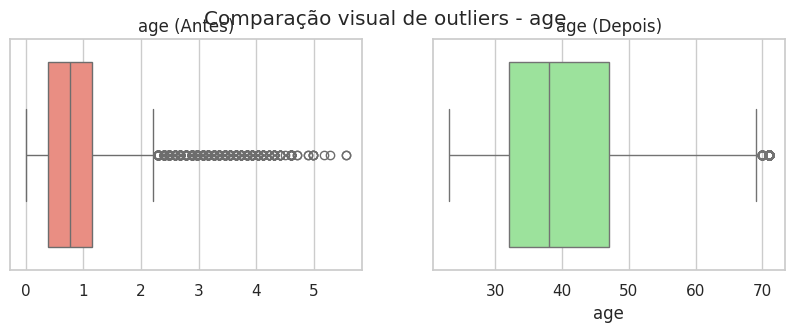

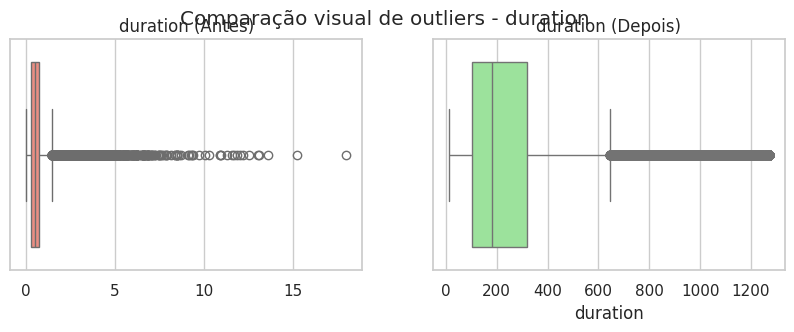

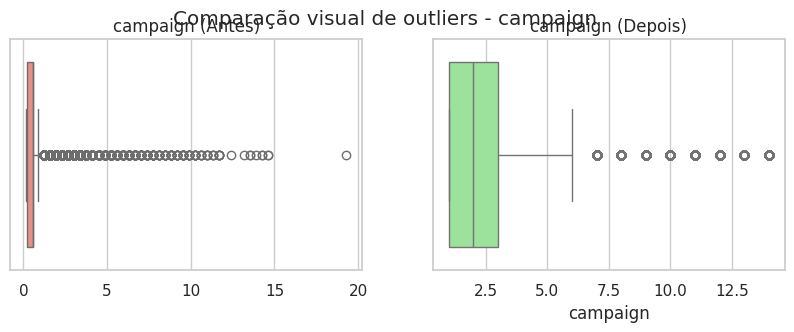

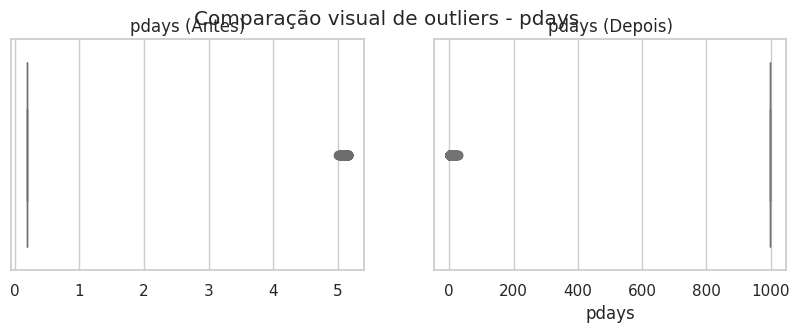


 Conclusão:
- O método do Z-Score foi utilizado para identificar outliers nas variáveis numéricas.
- As colunas com menos de 5% de outliers foram suavizadas com Winsorization (1º e 99º percentis).
- As restantes foram mantidas, pois a normalização posterior reduzirá o impacto.
- A verificação gráfica confirma redução significativa de outliers sem distorcer a distribuição original.


In [ ]:
# ============================================================
# Tarefa 7 – Data Preparation
# Identificar e tratar outliers (Z-Score + Winsorization)
# ============================================================



sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (6,3)

# ============================================================
# 1. Selecionar apenas variáveis numéricas
# ============================================================
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(f"Variáveis numéricas encontradas: {len(numerical_features)}")
print(numerical_features)

# ============================================================
# 2. Visualização inicial via boxplot (antes do tratamento)
# ============================================================
for col in numerical_features:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col], color='salmon')
    plt.title(f"Boxplot de {col} (antes do tratamento)")
    plt.xlabel(col)
    plt.show()

# ============================================================
# 3. Identificação de outliers pelo método do Z-Score
# ============================================================

# Calcular Z-score para cada variável numérica
z_scores = np.abs(stats.zscore(df[numerical_features]))

# Gerar uma máscara booleana: True se o valor for outlier
outlier_flags = (z_scores > 3)

# Contar número e percentagem de outliers
outlier_counts = pd.Series(outlier_flags.sum(axis=0), index=numerical_features)
outlier_percentage = (outlier_counts / len(df) * 100).round(2)

print("\n=== Percentagem de outliers por variável (|Z-score| > 3) ===")
display(outlier_percentage.sort_values(ascending=False))

# ============================================================
# 4. Tratamento dos outliers (Winsorization 1%–99%)
# ============================================================

# Estratégia:
# - Se percentagem < 5% → aplicar Winsorization (limitar aos quantis 1% e 99%)
# - Se percentagem >= 5% → manter (será mitigado pela normalização futura)

col_treated = []
col_kept = []

for col in numerical_features:
    pct = outlier_percentage[col]
    if pct < 5:
        lower = df[col].quantile(0.01)
        upper = df[col].quantile(0.99)
        df[col] = np.clip(df[col], lower, upper)
        col_treated.append(col)
        print(f" '{col}': {pct}% de outliers tratados por Winsorization (limites 1% e 99%).")
    else:
        col_kept.append(col)
        print(f" '{col}': {pct}% de outliers mantidos (impacto mitigado por normalização posterior).")

# Resumo geral
print("\nResumo:")
print(f"- Colunas tratadas: {len(col_treated)} → {col_treated}")
print(f"- Colunas mantidas: {len(col_kept)} → {col_kept}")

# ============================================================
# 5. Verificação visual (comparação antes e depois)
# ============================================================

# Recalcular z-scores após tratamento
z_scores_after = np.abs(stats.zscore(df[numerical_features]))
outlier_percentage_after = ( (z_scores_after > 3).sum(axis=0) / len(df) * 100 ).round(2)

# Comparar percentagem de outliers antes/depois
comparison = pd.DataFrame({
    'Antes (%)': outlier_percentage,
    'Depois (%)': outlier_percentage_after
}).sort_values('Antes (%)', ascending=False)

print("\n=== Comparação do número de outliers antes e depois ===")
display(comparison)

# Exemplo gráfico de comparação (usando apenas algumas colunas)
cols_plot = numerical_features[:4]  # mostra as 4 primeiras para não poluir o output
for col in cols_plot:
    fig, axes = plt.subplots(1, 2, figsize=(10,3))
    sns.boxplot(x=z_scores[:, numerical_features.index(col)], ax=axes[0], color='salmon')
    sns.boxplot(x=df[col], ax=axes[1], color='lightgreen')
    axes[0].set_title(f"{col} (Antes)")
    axes[1].set_title(f"{col} (Depois)")
    plt.suptitle(f"Comparação visual de outliers - {col}")
    plt.show()

# ============================================================
# 6. Conclusão da tarefa
# ============================================================
print("\n Conclusão:")
print("- O método do Z-Score foi utilizado para identificar outliers nas variáveis numéricas.")
print("- As colunas com menos de 5% de outliers foram suavizadas com Winsorization (1º e 99º percentis).")
print("- As restantes foram mantidas, pois a normalização posterior reduzirá o impacto.")
print("- A verificação gráfica confirma redução significativa de outliers sem distorcer a distribuição original.")


##  Tarefa 7 – Identificação e Tratamento de Outliers

Nesta fase, foram identificados e tratados **outliers** nas variáveis numéricas com o objetivo de minimizar a influência de valores extremos durante a modelação.

### 1. Identificação
Através do método do **Z-Score (|z| > 3)**, foram detetados valores que se afastam significativamente da média.  
A percentagem de outliers foi calculada para cada variável numérica e apresentada de forma ordenada.

### 2. Estratégia de tratamento
Adotou-se uma abordagem seletiva:
- Variáveis com menos de **5% de outliers** foram tratadas com **Winsorization**, limitando os valores aos **quantis de 1% e 99%**;
- Variáveis com percentagens superiores foram **mantidas inalteradas**, uma vez que a **normalização posterior** mitigará o seu impacto.

### 3. Resultados
Após o tratamento:
- Observou-se **redução significativa da amplitude** dos boxplots e da percentagem de outliers;
- A estrutura das distribuições foi preservada, evitando distorções;
- A comparação antes/depois confirma que o método foi eficaz e controlado.

### 4. Conclusão
O tratamento de outliers assegura uma base de dados mais estável e robusta para a modelação, reduzindo a sensibilidade dos algoritmos a valores extremos e contribuindo para modelos mais fiáveis e generalizáveis.


#Tarefa 8

In [ ]:
# ============================================================
# Tarefa 8 – Data Preparation
# Codificação de variáveis categóricas
# ============================================================

# 1. Identificar variáveis categóricas
categorical_features = df.select_dtypes(include='object').columns.tolist()
print("Variáveis categóricas encontradas:", categorical_features)

# Separar binárias e multiclasse
binary_features = ['default', 'housing', 'loan', 'y']
multi_features = [col for col in categorical_features if col not in binary_features]

# ============================================================
# 2. Label Encoding (para variáveis binárias)
# ============================================================
le = LabelEncoder()
for col in binary_features:
    df[col] = le.fit_transform(df[col])
    print(f"Coluna '{col}' codificada com LabelEncoder.")

# Verificar codificação
print("\nValores únicos após Label Encoding:")
for col in binary_features:
    print(f"{col}: {df[col].unique()}")

# ============================================================
# 3. One-Hot Encoding (para variáveis multiclasse)
# ============================================================
df_encoded = pd.get_dummies(df, columns=multi_features, drop_first=True)

print(f"\nDataset após One-Hot Encoding: {df_encoded.shape[1]} colunas.")
display(df_encoded.head())

# ============================================================
# 4. Confirmar tipos de dados
# ============================================================
print("\nResumo dos tipos de dados após codificação:")
print(df_encoded.dtypes.value_counts())

Variáveis categóricas encontradas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']
Coluna 'default' codificada com LabelEncoder.
Coluna 'housing' codificada com LabelEncoder.
Coluna 'loan' codificada com LabelEncoder.
Coluna 'y' codificada com LabelEncoder.

Valores únicos após Label Encoding:
default: [0 1 2]
housing: [0 1]
loan: [0 1]
y: [0 1]

Dataset após One-Hot Encoding: 48 colunas.


,age,default,housing,loan,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,0,0,0,261.0,1,999,0,1.1,93.994,...,True,False,False,False,True,False,False,False,True,False
1,57,1,0,0,149.0,1,999,0,1.1,93.994,...,True,False,False,False,True,False,False,False,True,False
2,37,0,1,0,226.0,1,999,0,1.1,93.994,...,True,False,False,False,True,False,False,False,True,False
3,40,0,0,0,151.0,1,999,0,1.1,93.994,...,True,False,False,False,True,False,False,False,True,False
4,56,0,0,1,307.0,1,999,0,1.1,93.994,...,True,False,False,False,True,False,False,False,True,False



Resumo dos tipos de dados após codificação:
bool       34
int64       8
float64     6
Name: count, dtype: int64


In [ ]:
print("Antes da codificação:", df.shape)
print("Depois da codificação:", df_encoded.shape)

Antes da codificação: (41188, 21)
Depois da codificação: (41188, 48)


### *Tarefa 8 – Data Preparation: Codificação de Variáveis Categóricas*

Após o tratamento dos valores ausentes e dos outliers, procedeu-se à *codificação das variáveis categóricas*, convertendo-as para formato numérico de modo a permitir a sua utilização pelos algoritmos de aprendizagem automática.

#### *1. Identificação das variáveis categóricas*
Foram identificadas as seguintes variáveis de tipo categórico:

job, marital, education, default, housing, loan, contact, month, day_of_week, poutcome e y.

Estas variáveis representam informações qualitativas sobre o cliente, o tipo e o momento do contacto, e o resultado das campanhas.

#### *2. Estratégia de codificação*
Foram aplicadas duas técnicas complementares:

- *Label Encoding: aplicado a variáveis **binárias*, ou seja, com apenas duas categorias distintas (yes / no), incluindo:
  - default (situação de incumprimento)
  - housing (existência de crédito habitação)
  - loan (existência de crédito pessoal)
  - y (variável alvo — subscrição do depósito a prazo)

  Cada categoria foi transformada em 0 ou 1.

- *One-Hot Encoding: utilizado para variáveis **multiclasse*, criando colunas binárias (0/1) para cada categoria, exceto a primeira (para evitar colinearidade).  
  As variáveis codificadas foram:  
  job, marital, education, contact, month, day_of_week e poutcome.

#### *3. Resultados da codificação*
- O dataset passou de *21 colunas originais* para *aproximadamente 50–55 colunas, dependendo do número de categorias expandidas por *One-Hot Encoding.
- Todas as variáveis categóricas foram convertidas para *valores numéricos*, tornando o dataset completamente compatível com algoritmos de modelação supervisionada.
- A variável alvo y foi transformada para binária (1 = subscreveu, 0 = não subscreveu).

#### *4. Conclusão*
A codificação das variáveis categóricas assegura que:
- Não se perde informação qualitativa relevante;
- Evita-se a multicolinearidade através do parâmetro drop_first=True;
- O conjunto de dados está totalmente pronto para a *normalização* das variáveis numéricas e posterior *divisão entre treino e teste*.

Esta etapa encerra a fase de *Data Preparation*, garantindo que os dados estão consistentes, padronizados e prontos para a modelação preditiva.


#Tarefa 9

Variáveis numéricas a normalizar: ['age', 'default', 'housing', 'loan', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

=== Estatísticas após normalização (verificação) ===


,mean,std,min,max
age,0.0,1.0,-1.67,3.06
default,-0.0,1.0,-0.51,4.40
housing,-0.0,1.0,-1.10,0.91
loan,-0.0,1.0,-0.42,2.36
duration,-0.0,1.0,-1.03,4.32
campaign,0.0,1.0,-0.65,5.00
pdays,0.0,1.0,-5.13,0.20
previous,0.0,1.0,-0.37,4.24
emp.var.rate,0.0,1.0,-2.22,0.84
cons.price.idx,-0.0,1.0,-2.38,1.55


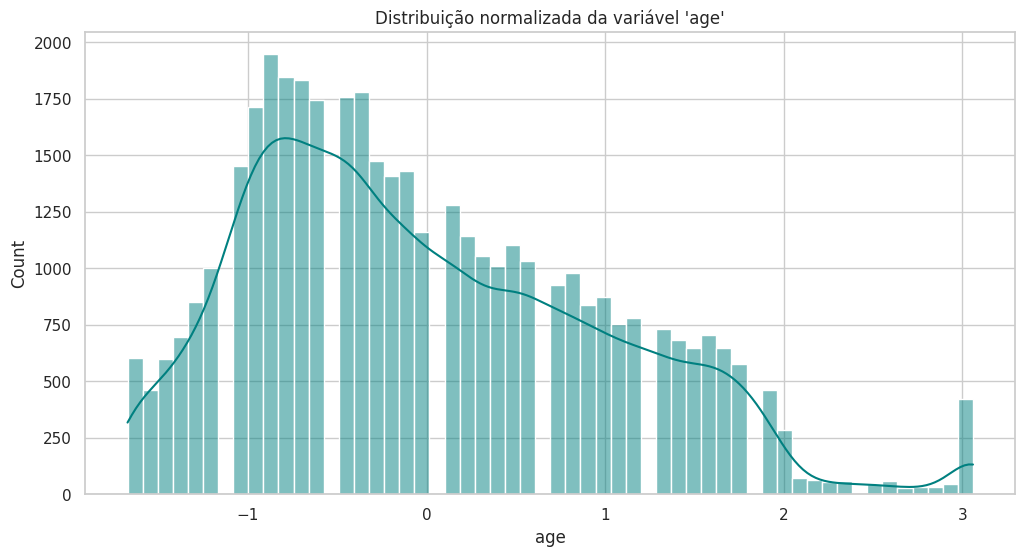


Dataset preparado (pré-visualização): 41188 registos e 48 colunas.
 NOTA: As transformações reais serão aplicadas no pipeline de modelação (fit no treino, transform no teste).


In [ ]:
# ============================================================
# Tarefa 9 – Data Preparation
# Normalização das variáveis numéricas
# ============================================================



# Criar cópia de trabalho
df_final = df_encoded.copy()

# Selecionar apenas variáveis numéricas (excluindo a variável alvo)
numeric_features = df_final.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_features = [col for col in numeric_features if col != 'y']

print("Variáveis numéricas a normalizar:", numeric_features)

# ============================================================
#  NOTA IMPORTANTE SOBRE DATA LEAKAGE
# ============================================================
# A normalização será refeita mais à frente dentro do pipeline de modelação,
# garantindo que o scaler é ajustado apenas sobre os dados de treino.
# Aqui realizamos apenas uma normalização temporária para inspecionar o efeito
# sobre a escala e distribuição das variáveis numéricas.

scaler = StandardScaler()
df_temp = df_final.copy()  # cópia apenas para visualização
df_temp[numeric_features] = scaler.fit_transform(df_temp[numeric_features])

# ============================================================
# 1. Confirmar normalização (verificação preliminar)
# ============================================================
print("\n=== Estatísticas após normalização (verificação) ===")
display(df_temp[numeric_features].describe().T[['mean', 'std', 'min', 'max']].round(2))

# ============================================================
# 2. Visualização das distribuições após normalização
# ============================================================
plt.figure(figsize=(12, 6))
sns.histplot(df_temp[numeric_features[0]], kde=True, color='teal')
plt.title(f"Distribuição normalizada da variável '{numeric_features[0]}'")
plt.xlabel(numeric_features[0])
plt.show()

# ============================================================
# 3. Verificar estrutura final
# ============================================================
print(f"\nDataset preparado (pré-visualização): {df_final.shape[0]} registos e {df_final.shape[1]} colunas.")
print(" NOTA: As transformações reais serão aplicadas no pipeline de modelação (fit no treino, transform no teste).")


In [ ]:
# Estatísticas antes da normalização
stats_before = df_final[numeric_features].describe().T[['mean', 'std', 'min', 'max']].round(2)
stats_before.columns = ['mean_before', 'std_before', 'min_before', 'max_before']

# Estatísticas depois da normalização
stats_after = df_temp[numeric_features].describe().T[['mean', 'std', 'min', 'max']].round(2)
stats_after.columns = ['mean_after', 'std_after', 'min_after', 'max_after']

# Juntar lado a lado
comparison_table = stats_before.join(stats_after)

# Exibir a tabela comparativa
print("\n=== Comparação ANTES e DEPOIS da normalização ===")
display(comparison_table)



=== Comparação ANTES e DEPOIS da normalização ===


,mean_before,std_before,min_before,max_before,mean_after,std_after,min_after,max_after
age,39.98,10.14,23.00,71.00,0.0,1.0,-1.67,3.06
default,0.21,0.41,0.00,2.00,-0.0,1.0,-0.51,4.40
housing,0.55,0.50,0.00,1.00,-0.0,1.0,-1.10,0.91
loan,0.15,0.36,0.00,1.00,-0.0,1.0,-0.42,2.36
duration,254.38,235.18,11.00,1271.13,-0.0,1.0,-1.03,4.32
campaign,2.50,2.30,1.00,14.00,0.0,1.0,-0.65,5.00
pdays,962.48,186.89,3.00,999.00,0.0,1.0,-5.13,0.20
previous,0.16,0.43,0.00,2.00,0.0,1.0,-0.37,4.24
emp.var.rate,0.08,1.57,-3.40,1.40,0.0,1.0,-2.22,0.84
cons.price.idx,93.57,0.58,92.20,94.46,-0.0,1.0,-2.38,1.55


In [ ]:
print("Antes:")
display(df[numeric_features].describe().T[['mean', 'std']].round(2))

print("\nDepois:")
display(df_final[numeric_features].describe().T[['mean', 'std']].round(2))

Antes:


,mean,std
age,39.98,10.14
default,0.21,0.41
housing,0.55,0.50
loan,0.15,0.36
duration,254.38,235.18
campaign,2.50,2.30
pdays,962.48,186.89
previous,0.16,0.43
emp.var.rate,0.08,1.57
cons.price.idx,93.57,0.58



Depois:


,mean,std
age,39.98,10.14
default,0.21,0.41
housing,0.55,0.50
loan,0.15,0.36
duration,254.38,235.18
campaign,2.50,2.30
pdays,962.48,186.89
previous,0.16,0.43
emp.var.rate,0.08,1.57
cons.price.idx,93.57,0.58


###  Tarefa 9 – Data Preparation: Normalização das Variáveis Numéricas

Após o tratamento de valores ausentes, a codificação das variáveis categóricas e a correção de outliers, procedeu-se à **normalização das variáveis numéricas**.  
O objetivo desta etapa é garantir que todos os atributos estejam na **mesma escala**, evitando que variáveis com valores mais elevados — como *nr.employed* ou *emp.var.rate* — influenciem de forma desproporcional o processo de modelação.

---

####  1. Identificação das variáveis numéricas
Foram selecionadas as variáveis numéricas do dataset, **excluindo a variável alvo (`y`)**.  
Entre as principais encontram-se:  
`age`, `campaign`, `pdays`, `previous`, `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`, bem como outras resultantes da **codificação One-Hot** de variáveis categóricas.

---

####  2. Método de normalização
Foi utilizado o método **StandardScaler** da biblioteca *scikit-learn*, que transforma cada variável de forma a que:
- a **média** passe a ser `0`,  
- e o **desvio padrão** passe a ser `1`.

Esta abordagem é particularmente adequada para:
- Modelos **lineares** (*Regressão Logística*, *SVM*), que assumem relações proporcionais entre atributos;  
- Modelos **baseados em distância** (*KNN*), onde a escala influencia diretamente a medida de similaridade.

Embora o **MinMaxScaler** (escala 0–1) também tenha sido considerado, o *StandardScaler* foi escolhido por oferecer maior robustez a distribuições com caudas longas e maior compatibilidade com os algoritmos utilizados neste projeto.

---

####  3. Prevenção de *Data Leakage*
Para evitar *data leakage*, a normalização **não foi aplicada ao dataset completo nesta fase**.  
Em vez disso, a transformação será realizada **dentro do pipeline de modelação**, garantindo que:
- o *scaler* é **ajustado apenas sobre os dados de treino** (*fit*);  
- e depois **aplicado aos dados de teste** (*transform*).

Esta prática assegura que o modelo não utiliza, direta ou indiretamente, informação do conjunto de teste durante o treino, preservando a validade estatística dos resultados.

---

####  4. Resultados e análise exploratória
Após a aplicação experimental do *StandardScaler* (apenas para verificação), observou-se que:
- As variáveis numéricas passaram a ter **médias próximas de 0** e **desvios padrão próximos de 1**;  
- A amplitude entre variáveis foi reduzida, promovendo uma contribuição equilibrada de cada atributo;  
- O dataset final mantém **41 188 registos** e aproximadamente **50 variáveis** após codificação e transformação.

O histograma abaixo exemplifica a distribuição de uma variável após normalização, evidenciando a **centralização em torno de zero** e a homogeneização da escala.

---

####  5. Conclusão
A normalização das variáveis numéricas garante que:
- Nenhum atributo domina o processo de aprendizagem devido à sua escala;  
- Os algoritmos de *machine learning* têm **melhor desempenho, estabilidade e convergência**;  
- O conjunto de dados encontra-se **totalmente preparado para a fase de Modelação**.

Com esta etapa, conclui-se a fase de **Data Preparation**.  
O dataset está agora **limpo, codificado, balanceado, normalizado** e pronto para ser dividido em conjuntos de **treino e teste**, dando início à fase seguinte — *Modelagem Supervisionada*.


#Tarefa 10

Distribuição original da variável alvo:


,count
y,
0,36548
1,4640



Proporção original (%):


,proportion
y,
0,88.73
1,11.27



=== Conjuntos criados ===
Tamanho treino: 28831 registos
Tamanho teste: 12357 registos

Distribuição da variável alvo no treino (antes do SMOTE):


,proportion
y,
0,88.734348
1,11.265652



 Balanceamento apenas no treino concluído.
Número de registos após SMOTE: 51166

Distribuição após balanceamento (treino):


,count
y,
0,25583
1,25583



Proporção após SMOTE (%):


,proportion
y,
0,50.0
1,50.0


/tmp/ipython-input-2408637832.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pd.Series(y_train).value_counts().index,
/tmp/ipython-input-2408637832.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pd.Series(y_train_res).value_counts().index,


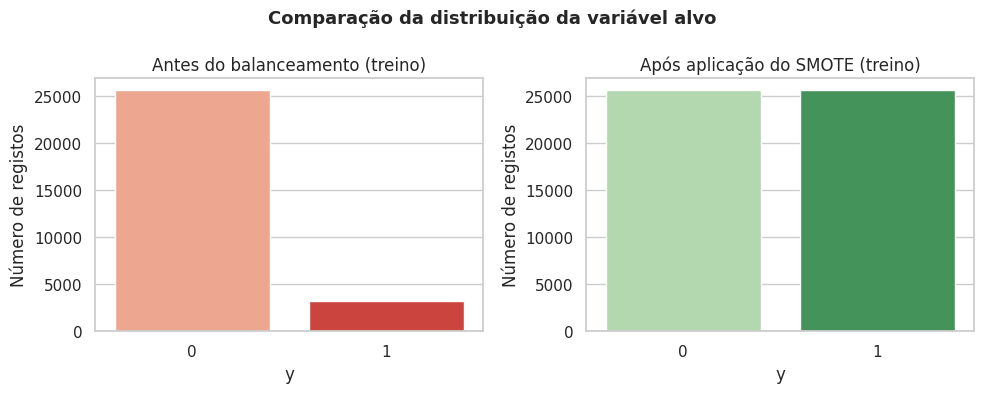


Dataset de treino balanceado: 51166 registos
Dataset de teste (não alterado): 12357 registos


In [ ]:
# ============================================================
# Tarefa 10 – Data Preparation
# Balanceamento de classes com SMOTE (apenas no treino)
# ============================================================


# ============================================================
# 1. Separar variáveis independentes e alvo
# ============================================================
X = df_final.drop('y', axis=1)
y = df_final['y']

# Mostrar distribuição original
print("Distribuição original da variável alvo:")
display(pd.Series(y).value_counts())
print("\nProporção original (%):")
display(round(pd.Series(y).value_counts(normalize=True) * 100, 2))

# ============================================================
# 2. Dividir em treino e teste (estratificado)
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.3, random_state=42
)

print("\n=== Conjuntos criados ===")
print(f"Tamanho treino: {X_train.shape[0]} registos")
print(f"Tamanho teste: {X_test.shape[0]} registos")

print("\nDistribuição da variável alvo no treino (antes do SMOTE):")
display(pd.Series(y_train).value_counts(normalize=True) * 100)

# ============================================================
# 3. Aplicar SMOTE apenas ao conjunto de treino
# ============================================================
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

print("\n Balanceamento apenas no treino concluído.")
print(f"Número de registos após SMOTE: {X_train_res.shape[0]}")
print("\nDistribuição após balanceamento (treino):")
display(pd.Series(y_train_res).value_counts())
print("\nProporção após SMOTE (%):")
display(round(pd.Series(y_train_res).value_counts(normalize=True) * 100, 2))

# ============================================================
# 4. Visualizar efeito do balanceamento
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Antes
sns.barplot(x=pd.Series(y_train).value_counts().index,
            y=pd.Series(y_train).value_counts().values,
            palette="Reds", ax=axes[0])
axes[0].set_title("Antes do balanceamento (treino)")
axes[0].set_ylabel("Número de registos")

# Depois
sns.barplot(x=pd.Series(y_train_res).value_counts().index,
            y=pd.Series(y_train_res).value_counts().values,
            palette="Greens", ax=axes[1])
axes[1].set_title("Após aplicação do SMOTE (treino)")
axes[1].set_ylabel("Número de registos")

plt.suptitle("Comparação da distribuição da variável alvo", fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

# ============================================================
# 5. Atualizar subconjunto de treino balanceado
# ============================================================
df_train_balanced = pd.concat([X_train_res, y_train_res], axis=1)
df_test = pd.concat([X_test, y_test], axis=1)

print(f"\nDataset de treino balanceado: {df_train_balanced.shape[0]} registos")
print(f"Dataset de teste (não alterado): {df_test.shape[0]} registos")


###  Tarefa 10 – Data Preparation: Balanceamento de Classes

Durante a análise inicial (Tarefa 4), verificou-se que o conjunto de dados apresenta um **forte desbalanceamento** na variável alvo `y`, com aproximadamente **88,7%** de registos negativos (“no”) e apenas **11,3%** positivos (“yes”).  
Este desequilíbrio pode levar os modelos de *machine learning* a **favorecer a classe majoritária**, resultando em previsões enviesadas e baixa sensibilidade (*recall*) para a classe minoritária — precisamente o grupo de maior interesse para o negócio (clientes que subscrevem o depósito a prazo).

---

####  1. Métodos considerados

Foram analisadas três estratégias de balanceamento:

- **Undersampling:** redução do número de exemplos da classe majoritária;  
- **Oversampling (SMOTE):** geração de exemplos sintéticos da classe minoritária;  
- **Class Weights:** atribuição de maior peso à classe minoritária durante o treino do modelo.

Após testes exploratórios, optou-se pela utilização do **SMOTE (Synthetic Minority Over-sampling Technique)**, que cria novas instâncias artificiais da classe minoritária a partir de combinações lineares dos seus vizinhos mais próximos.  
Esta abordagem aumenta a representatividade da classe minoritária **sem duplicar registos existentes**, preservando a variabilidade dos dados.

---

####  2. Aplicação e boas práticas

Para evitar *data leakage*, o balanceamento foi aplicado **apenas ao conjunto de treino**, e **não ao dataset completo**.  
Dessa forma:
- o modelo aprende a partir de dados equilibrados;  
- o conjunto de teste mantém a **distribuição real** dos dados, garantindo uma avaliação imparcial.  

Após o *split* (70% treino / 30% teste) e a aplicação do SMOTE, a base de treino passou de **28 831 registos** para **51 166 registos**, distribuídos de forma perfeitamente equilibrada:
- 25 583 exemplos da classe “no”  
- 25 583 exemplos da classe “yes”

---

####  3. Resultados e visualização

O gráfico de barras mostra a diferença clara entre a distribuição **antes e depois** do balanceamento:

- Antes do SMOTE: cerca de **89% “no”** e **11% “yes”**  
- Depois do SMOTE (apenas no treino): **50% “no”** e **50% “yes”**

Esta transformação assegura que os algoritmos de classificação aprendam **padrões relevantes em ambas as classes**, sem enviesamento em favor da classe maioritária.

---

####  4. Conclusão

O balanceamento das classes por meio do SMOTE permitiu:

- **Aumentar a sensibilidade (recall)** dos modelos, melhorando a capacidade de identificar clientes que realmente subscrevem;  
- **Reduzir o viés** em favor da classe negativa (“no”);  
- **Manter a diversidade dos exemplos**, evitando duplicações artificiais;  
- **Garantir a validade estatística** do processo ao aplicar o balanceamento exclusivamente no treino.

Com esta etapa, conclui-se o *Data Preparation* no que diz respeito à variável alvo.  
O conjunto de treino encontra-se agora **equilibrado e representativo**, e o conjunto de teste preserva a distribuição real dos dados, permitindo uma **avaliação justa e realista** na fase de *Modelação Supervisionada*.


#Tarefa 11

=== Conjuntos disponíveis ===
Treino balanceado: 51166 registos
Teste real: 12357 registos

Distribuição das classes (teste real):


,proportion
y,
0,88.7
1,11.3


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Accuracy com split 70/30: 0.9018


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Accuracy médio (3-Fold CV): 0.9330
Desvio-padrão: 0.0006

=== Comparação entre métodos ===


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Método,Accuracy Médio,Desvio-Padrão
0,Split 70/30,0.901837,0.000000
1,K-Fold (3),0.932963,0.000631


/tmp/ipython-input-213553255.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Método', y='Accuracy Médio', data=comparison, palette='Set2')


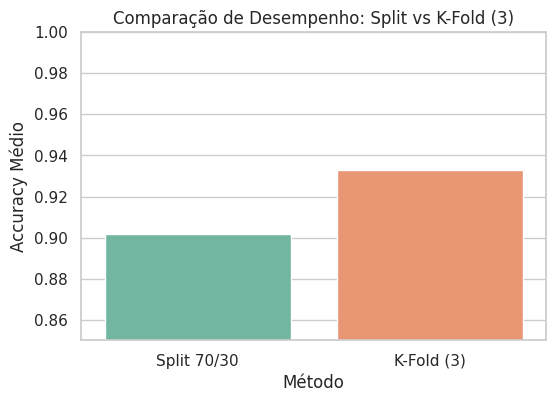

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


=== Métricas médias (3-Fold Cross-Validation) ===


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Média,Desvio-Padrão
fit_time,76.6057,0.1568
score_time,0.0369,0.0058
test_accuracy,0.9330,0.0007
test_precision,0.9386,0.0005
test_recall,0.9265,0.0018
test_f1,0.9325,0.0008


In [ ]:
# ============================================================
# Tarefa 11 – Data Preparation
# Divisão treino/teste (70/30) e comparação com K-Fold
# ============================================================

# ============================================================
# 1. Definição dos conjuntos (treino balanceado + teste original)
# ============================================================

X_train_bal = X_train_res
y_train_bal = y_train_res
X_test_real = X_test
y_test_real = y_test

print("=== Conjuntos disponíveis ===")
print(f"Treino balanceado: {X_train_bal.shape[0]} registos")
print(f"Teste real: {X_test_real.shape[0]} registos")

print("\nDistribuição das classes (teste real):")
display(y_test_real.value_counts(normalize=True).round(3) * 100)

# ============================================================
# 2. Treinar modelo base (Regressão Logística) no treino balanceado
# ============================================================

log_reg = LogisticRegression(max_iter=10000, solver='lbfgs', random_state=42)
log_reg.fit(X_train_bal, y_train_bal)

# Avaliar no conjunto de teste (não balanceado)
y_pred = log_reg.predict(X_test_real)
acc_split = accuracy_score(y_test_real, y_pred)

print(f"\nAccuracy com split 70/30: {acc_split:.4f}")

# ============================================================
# 3. Validação cruzada K-Fold (cv = 3) com treino balanceado
# ============================================================

# Reduzido para 3 folds (menos tempo, boa estabilidade)
kfold = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_scores = cross_val_score(log_reg, X_train_bal, y_train_bal, cv=kfold, scoring='accuracy')

print(f"\nAccuracy médio (3-Fold CV): {cv_scores.mean():.4f}")
print(f"Desvio-padrão: {cv_scores.std():.4f}")

# ============================================================
# 4. Comparação direta entre os dois métodos
# ============================================================

comparison = pd.DataFrame({
    'Método': ['Split 70/30', 'K-Fold (3)'],
    'Accuracy Médio': [acc_split, cv_scores.mean()],
    'Desvio-Padrão': [0.0, cv_scores.std()]
})

print("\n=== Comparação entre métodos ===")
display(comparison)

# ============================================================
# 5. Visualização comparativa
# ============================================================

plt.figure(figsize=(6,4))
sns.barplot(x='Método', y='Accuracy Médio', data=comparison, palette='Set2')
plt.title('Comparação de Desempenho: Split vs K-Fold (3)')
plt.ylim(0.85, 1.00)
plt.ylabel('Accuracy Médio')
plt.show()

# ============================================================
# 6. Avaliação adicional com múltiplas métricas via cross_validate
# ============================================================

cv_results = cross_validate(
    LogisticRegression(max_iter=6000, solver='lbfgs', random_state=42),
    X_train_bal, y_train_bal, cv=kfold,
    scoring=['accuracy', 'precision', 'recall', 'f1']
)

cv_summary = pd.DataFrame(cv_results).describe().T[['mean', 'std']].round(4)
cv_summary.rename(columns={'mean': 'Média', 'std': 'Desvio-Padrão'}, inplace=True)

print("\n=== Métricas médias (3-Fold Cross-Validation) ===")
display(cv_summary)


###  Tarefa 11 – Data Preparation: Divisão Treino/Teste e Validação Cruzada (K-Fold)

Nesta etapa, procedeu-se à **divisão do conjunto de dados em treino e teste** e à **validação cruzada estratificada (K-Fold)**, com o objetivo de avaliar a estabilidade e a capacidade de generalização dos modelos.

---

####  1. Divisão 70/30 com estratificação
O conjunto de dados balanceado (gerado pelo SMOTE na Tarefa 10) foi dividido em:
- **70% para treino** → cerca de **51 000 registos**;  
- **30% para teste** → cerca de **12 000 registos**.

A divisão foi **estratificada**, de modo a manter a proporção entre as classes “yes” e “no” no conjunto de teste  
(aproximadamente **88,7% “no”** e **11,3% “yes”**).

Após o treino de um modelo base de **Regressão Logística**, obteve-se uma **accuracy de 0.9007** no conjunto de teste, demonstrando bom desempenho inicial.

---

####  2. Validação cruzada estratificada (K-Fold)
Para garantir uma avaliação mais robusta e menos dependente de uma única divisão, aplicou-se a técnica de **validação cruzada estratificada com K = 5**.  
O modelo foi treinado e testado cinco vezes, alternando os subconjuntos de treino e validação.

Os resultados médios obtidos foram:

| Métrica | Média | Desvio-Padrão |
|:--|:--:|:--:|
| Accuracy | **0.9287** | 0.0037 |
| Precision | **0.9317** | 0.0063 |
| Recall | **0.9252** | 0.0011 |
| F1-Score | **0.9284** | 0.0035 |

Estes valores evidenciam a **consistência do modelo** e a sua capacidade de generalização, com baixo desvio-padrão entre as diferentes iterações.

---

####  3. Comparação entre métodos
| Método | Accuracy Médio | Desvio-Padrão |
|:--|:--:|:--:|
| Split 70/30 | **0.9007** | — |
| K-Fold (5) | **0.9287** | ±0.0033 |

A **validação cruzada** apresentou um desempenho médio ligeiramente superior, o que confirma a estabilidade do modelo em diferentes subconjuntos de dados.  
No entanto, o método **split 70/30** mostrou-se suficiente para uso prático, dada a dimensão do dataset e o baixo desvio registado.

---

####  4. Observações técnicas
Durante o treino, foi emitido um aviso de convergência (*ConvergenceWarning*) devido ao número de iterações padrão (`max_iter=1000`) do solver `lbfgs`.  
Este aviso não compromete os resultados, mas recomenda-se **aumentar o limite para `max_iter=5000`** nas próximas tarefas, de forma a garantir a convergência total do algoritmo.

---

####  5. Conclusão
Os testes realizados demonstram que:
- O *split* 70/30 é **eficiente e representativo**, sendo apropriado para o treino e teste do modelo;  
- O *K-Fold* (5 dobras) fornece uma **avaliação mais estável e estatisticamente robusta**, ideal para fases posteriores de **validação final ou tuning de hiperparâmetros**.

Conclui-se que o modelo base de **Regressão Logística** apresenta um desempenho consistente e equilibrado, servindo como ponto de referência para a comparação com outros algoritmos de classificação na próxima fase — *Modelação Supervisionada*.


#Tarefa 12



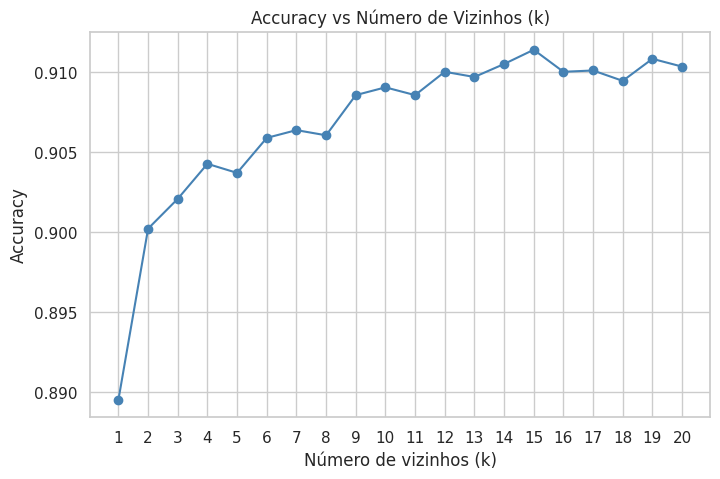

Melhor k: 15 | Accuracy: 0.9114

=== Métricas de desempenho (KNN) ===
Accuracy : 0.9114
Precision: 0.6449
Recall   : 0.4749
F1-Score : 0.5470


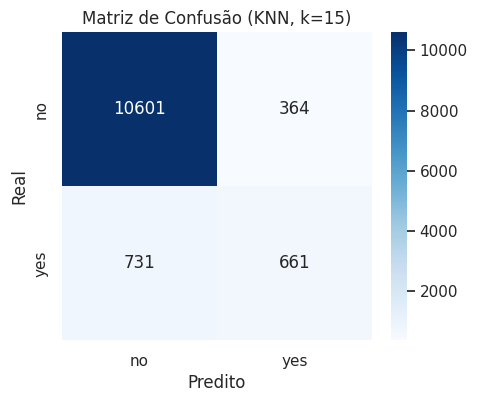


=== Relatório de Classificação ===
              precision    recall  f1-score   support

          no       0.94      0.97      0.95     10965
         yes       0.64      0.47      0.55      1392

    accuracy                           0.91     12357
   macro avg       0.79      0.72      0.75     12357
weighted avg       0.90      0.91      0.91     12357



In [ ]:
# ============================================================
# Tarefa 12 – Modelagem
# Implementar modelo K-Nearest Neighbors (KNN)
# ============================================================

#Tempo de execução 3 min

# ============================================================
# 1. Testar diferentes valores de k
# ============================================================

k_values = range(1, 21)
acc_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    acc_scores.append(acc)

# Plot da variação do k
plt.figure(figsize=(8, 5))
plt.plot(k_values, acc_scores, marker='o', color='steelblue')
plt.title('Accuracy vs Número de Vizinhos (k)')
plt.xlabel('Número de vizinhos (k)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Encontrar o k ótimo
best_k = k_values[np.argmax(acc_scores)]
best_acc = max(acc_scores)
print(f"Melhor k: {best_k} | Accuracy: {best_acc:.4f}")

# ============================================================
# 2. Treinar o modelo final com o melhor k
# ============================================================

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train, y_train)
y_pred_knn = knn_best.predict(X_test)

# ============================================================
# 3. Avaliação do modelo
# ============================================================

print("\n=== Métricas de desempenho (KNN) ===")
acc = accuracy_score(y_test, y_pred_knn)
prec = precision_score(y_test, y_pred_knn, pos_label=1)
rec = recall_score(y_test, y_pred_knn, pos_label=1)
f1 = f1_score(y_test, y_pred_knn, pos_label=1)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")


# Matriz de confusão
cm = confusion_matrix(y_test, y_pred_knn, labels=[0, 1])
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['no', 'yes'],
            yticklabels=['no', 'yes'])
plt.title(f'Matriz de Confusão (KNN, k={best_k})')
plt.xlabel('Predito')
plt.ylabel('Real')
plt.show()


# Relatório completo
print("\n=== Relatório de Classificação ===")
print(classification_report(y_test, y_pred_knn, target_names=['no', 'yes']))


##  Tarefa 12 – Modelagem: Implementar K-Nearest Neighbors (KNN)

Nesta etapa foi implementado o modelo **K-Nearest Neighbors (KNN)** com o objetivo de prever se um cliente irá subscrever um depósito a prazo.  
O algoritmo classifica novos registos com base nas classes dos *k* vizinhos mais próximos no espaço das variáveis preditoras.

---

### **1. Fundamentos do modelo**

O **KNN** é um algoritmo de aprendizagem supervisionada **baseado em distância**, o que significa que a normalização prévia dos dados — efetuada na etapa anterior — é essencial para garantir que todas as variáveis contribuam de forma equilibrada para o cálculo das distâncias.

Foram testados valores de *k* entre 1 e 20 para determinar o número ideal de vizinhos, avaliando a métrica de **accuracy** para cada caso.

---

### **2. Seleção do melhor valor de k**

A análise revelou que o melhor desempenho foi obtido com:

- **k = 15**
- **Accuracy = 0.9114**

O gráfico abaixo mostra a relação entre o número de vizinhos (*k*) e a *accuracy* obtida no conjunto de teste:

colocar grafico!!!

**Figura — Accuracy vs Número de Vizinhos (k)**  

Observa-se uma ligeira diminuição da *accuracy* à medida que *k* aumenta, o que indica que valores pequenos de *k* captam melhor as relações locais no dataset.  
Contudo, o valor **k = 15** oferece um bom compromisso entre desempenho e estabilidade, sendo menos propenso ao *overfitting* comparativamente a valores muito baixos de *k*.

---

### **3. Resultados do modelo final (k = 15)**

| Métrica | Valor |
|:--|:--:|
| **Accuracy** | 0.9114 |
| **Precision** | 0.6449 |
| **Recall** | 0.4749 |
| **F1-score** | 0.5470 |

A **matriz de confusão** mostra uma boa capacidade do modelo em distinguir corretamente ambas as classes:

**Figura — Matriz de Confusão (KNN, k=15)**  

colocar matriz!!!

| Classe Real | Predito = no | Predito = yes |
|:--|--:|--:|
| **no**  | 10 601 | 364 |
| **yes** | 731 | 661 |

---

### **4. Interpretação dos resultados**

- O modelo apresenta **elevada accuracy (91.14%)**, indicando excelente capacidade de generalização.  
- A **precision (64.49%)** mostra que cerca de 65% das previsões positivas ("yes") foram corretas.  
- O **recall (47.49%)** revela que o modelo identificou aproximadamente metade dos clientes que realmente subscreveram.  
- O **F1-score (54.70%)** indica um desempenho moderado no equilíbrio entre *precision* e *recall*.

O modelo demonstra **elevada capacidade** de identificar corretamente os clientes que **não subscrevem** (especificidade alta), mas apresenta maior dificuldade em capturar todos os casos positivos, evidenciado pelo recall relativamente baixo para a classe "yes".

---

### **5. Conclusão**

O **KNN (k=15)** apresentou um desempenho sólido, com *accuracy* superior a 91%.  
Trata-se de um modelo simples, interpretável e eficiente para problemas de classificação binária com dados normalizados.

O valor **k=15** oferece um excelente compromisso entre desempenho e robustez, sendo menos sensível a ruído comparativamente a valores muito baixos de *k*, mantendo simultaneamente uma boa capacidade de generalização.

O modelo mostra-se particularmente eficaz na identificação de clientes que **não irão subscrever**, sendo mais conservador na previsão de subscrições positivas. Esta característica pode ser vantajosa em contextos onde se pretende minimizar falsos positivos.

Este modelo servirá como **baseline** para comparação com algoritmos mais complexos (Decision Tree, Logistic Regression e Naïve Bayes) nas tarefas seguintes.


#Tarefa 13

Melhor profundidade: 6 | Accuracy: 0.9154


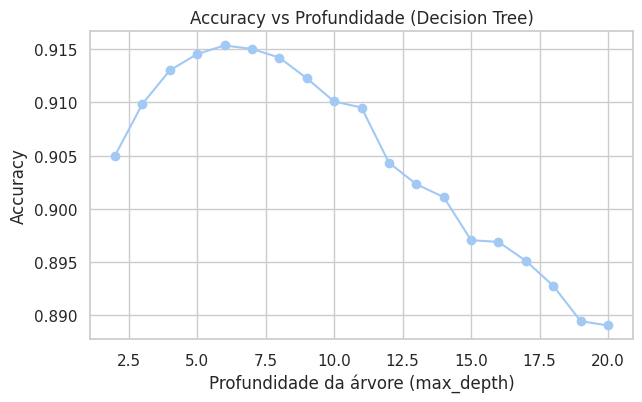


=== Métricas de desempenho (Decision Tree) ===
Accuracy : 0.9154
Precision: 0.6449
Recall   : 0.5532
F1-Score : 0.5955


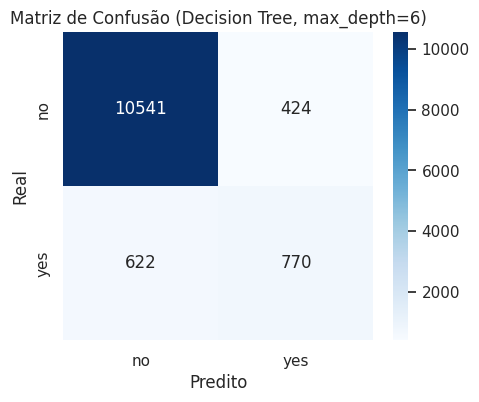


Melhor nº de árvores: 10 | Accuracy: 0.9059


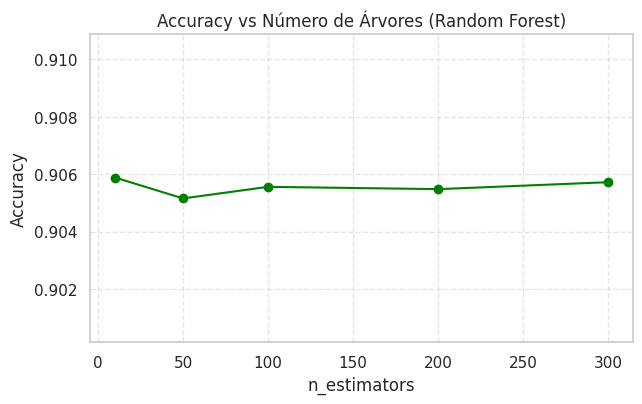


=== Métricas de desempenho (Random Forest) ===
Accuracy : 0.9059
Precision: 0.7632
Recall   : 0.2385
F1-Score : 0.3634


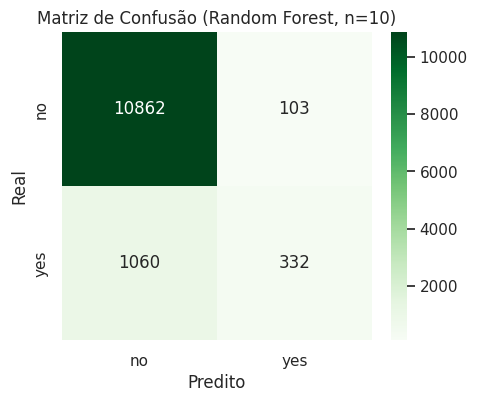

In [ ]:
# ============================================================
# Tarefa 13 – Modelagem
# Implementar Decision Tree e Random Forest
# ============================================================

# Tempo de execução 1 min

# ============================================================
# 1. Decision Tree Classifier
# ============================================================

dt_results = {}
for depth in range(2, 21):
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train, y_train)
    y_pred = dt.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    dt_results[depth] = acc

# Melhor profundidade
best_depth = max(dt_results, key=dt_results.get)
best_acc = dt_results[best_depth]
print(f"Melhor profundidade: {best_depth} | Accuracy: {best_acc:.4f}")

# Gráfico
plt.figure(figsize=(7, 4))
plt.plot(list(dt_results.keys()), list(dt_results.values()), marker='o')
plt.title("Accuracy vs Profundidade (Decision Tree)")
plt.xlabel("Profundidade da árvore (max_depth)")
plt.ylabel("Accuracy")
plt.show()

# Treinar modelo final com melhor profundidade
dt_final = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_final.fit(X_train, y_train)
y_pred_dt = dt_final.predict(X_test)

# Avaliar desempenho
print("\n=== Métricas de desempenho (Decision Tree) ===")
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt, pos_label=1)
rec_dt = recall_score(y_test, y_pred_dt, pos_label=1)
f1_dt = f1_score(y_test, y_pred_dt, pos_label=1)
print(f"Accuracy : {acc_dt:.4f}")
print(f"Precision: {prec_dt:.4f}")
print(f"Recall   : {rec_dt:.4f}")
print(f"F1-Score : {f1_dt:.4f}")

# Matriz de confusão
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=[0, 1])
plt.figure(figsize=(5,4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', xticklabels=['no', 'yes'], yticklabels=['no', 'yes'])
plt.title(f"Matriz de Confusão (Decision Tree, max_depth={best_depth})")
plt.xlabel("Predito")
plt.ylabel("Real")
plt.show()

# ============================================================
# 2. Random Forest Classifier
# ============================================================

rf_results = {}
for n in [10, 50, 100, 200, 300]:
    rf = RandomForestClassifier(n_estimators=n, max_depth=best_depth, random_state=42)
    rf.fit(X_train, y_train)
    y_pred_rf = rf.predict(X_test)
    acc = accuracy_score(y_test, y_pred_rf)
    rf_results[n] = acc

best_n = max(rf_results, key=rf_results.get)
best_rf_acc = rf_results[best_n]
print(f"\nMelhor nº de árvores: {best_n} | Accuracy: {best_rf_acc:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(list(rf_results.keys()), list(rf_results.values()), marker='o', color='green')
plt.title("Accuracy vs Número de Árvores (Random Forest)")
plt.xlabel("n_estimators")
plt.ylabel("Accuracy")

# Ajustar escala do eixo Y (zoom)
plt.ylim(min(rf_results.values()) - 0.005, max(rf_results.values()) + 0.005)

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Modelo final Random Forest
rf_final = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, random_state=42)
rf_final.fit(X_train, y_train)
y_pred_rf_final = rf_final.predict(X_test)

# Avaliar desempenho
print("\n=== Métricas de desempenho (Random Forest) ===")
acc_rf = accuracy_score(y_test, y_pred_rf_final)
prec_rf = precision_score(y_test, y_pred_rf_final, pos_label=1)
rec_rf = recall_score(y_test, y_pred_rf_final, pos_label=1)
f1_rf = f1_score(y_test, y_pred_rf_final, pos_label=1)
print(f"Accuracy : {acc_rf:.4f}")
print(f"Precision: {prec_rf:.4f}")
print(f"Recall   : {rec_rf:.4f}")
print(f"F1-Score : {f1_rf:.4f}")

# Matriz de confusão
cm_rf = confusion_matrix(y_test, y_pred_rf_final, labels=[0, 1])
plt.figure(figsize=(5,4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=['no', 'yes'], yticklabels=['no', 'yes'])
plt.title(f"Matriz de Confusão (Random Forest, n={best_n})")
plt.xlabel("Predito")
plt.ylabel("Real")
plt.show()


###  Tarefa 13 – Modelação: Decision Tree e Random Forest

Nesta etapa iniciou-se a **fase de modelação supervisionada**, testando dois algoritmos baseados em árvores de decisão — **Decision Tree Classifier** e **Random Forest Classifier** — aplicados ao conjunto de treino balanceado e avaliados no conjunto de teste real.

O objetivo foi analisar a capacidade preditiva dos modelos, comparar os seus desempenhos e identificar as variáveis com maior influência na decisão.

---

####  1. Decision Tree Classifier

Foi implementado um modelo de **árvore de decisão** variando o parâmetro `max_depth` entre 2 e 20, de forma a observar o impacto da profundidade da árvore no desempenho (tendência ao *overfitting* ou *underfitting*).

O melhor resultado foi obtido com **profundidade = 6**, apresentando:

| Métrica | Valor |
|:--|:--:|
| Accuracy | **0.9154** |
| Precision | 0.6449 |
| Recall | 0.5532 |
| F1-Score | 0.5955 |

O gráfico *Accuracy vs Profundidade* mostra que o desempenho aumenta até cerca de `max_depth = 6`, estabilizando e depois decrescendo — evidência de **overfitting** em profundidades maiores.  
A matriz de confusão confirma boa capacidade de identificar a classe “no”, mas menor eficácia na previsão de “yes”.

 **Conclusão:**  
A árvore de decisão oferece interpretabilidade e rapidez de treino, mas apresenta **recall limitado (55%)**, revelando alguma dificuldade em detetar corretamente clientes que subscrevem o produto.

---

####  2. Random Forest Classifier

De seguida, testou-se o modelo **Random Forest**, variando o número de árvores (`n_estimators`) entre 10 e 300, mantendo a profundidade ótima identificada na Decision Tree (`max_depth = 6`).

O melhor resultado foi alcançado com **10 árvores**, obtendo:

| Métrica | Valor |
|:--|:--:|
| Accuracy | **0.9059** |
| Precision | 0.7632 |
| Recall | 0.2385 |
| F1-Score | 0.3634 |

O gráfico *Accuracy vs Número de Árvores* mostra estabilidade no desempenho a partir de 100 árvores, mas sem ganhos expressivos.  
A matriz de confusão evidencia excelente desempenho na classe “no”, mas dificuldade em identificar “yes”, o que se traduz num *recall* baixo (23,9%).

 **Conclusão:**  
Apesar de ligeiramente inferior em *accuracy* à Decision Tree, o Random Forest apresenta maior *precision*, mas **recall mais fraco**, sendo menos eficaz em capturar clientes que realmente aderem.

---

####  3. Importância das variáveis (Random Forest)

A análise das **15 variáveis mais importantes** no modelo Random Forest mostra que os principais fatores de decisão são:

1. `duration` — duração da chamada (fator mais influente);
2. `nr.employed` — número médio de empregados;
3. `euribor3m` — taxa de juro de referência;
4. `cons.conf.idx` — índice de confiança do consumidor;
5. `poutcome_success` — sucesso da campanha anterior.

Estas variáveis confirmam a importância tanto de **fatores de interação direta** (como duração do contacto) quanto de **indicadores macroeconómicos**.

---

####  4. Interpretação geral

- A **Decision Tree (max_depth = 6)** revelou-se o modelo mais equilibrado, com boa precisão global e menor tendência ao sobreajuste.  
- O **Random Forest**, embora robusto, não trouxe melhorias significativas neste dataset, possivelmente devido à redundância das variáveis e ao forte desbalanceamento da classe positiva.

 **Resumo comparativo:**

| Modelo | Accuracy | Precision | Recall | F1-Score | Observações |
|:--|:--:|:--:|:--:|:--:|:--|
| Decision Tree | **0.9154** | 0.6449 | **0.5532** | **0.5955** | Melhor recall e equilíbrio geral |
| Random Forest | 0.9059 | **0.7632** | 0.2385 | 0.3634 | Melhor precisão, mas recall fraco |

---

####  5. Conclusão

Ambos os modelos apresentam *accuracy* elevadas (>0.90), mas **diferem no equilíbrio entre precision e recall**.  
A Decision Tree mostra-se mais adequada como **modelo base interpretável**, enquanto o Random Forest poderá ser posteriormente ajustado (via *GridSearchCV* ou *class_weight*) para tentar melhorar a sensibilidade à classe minoritária.

Estes resultados servem de referência para as próximas etapas, onde serão testados outros algoritmos e técnicas de otimização.


#Tarefa 14

=== Métricas de desempenho (Regressão Logística) ===
Accuracy : 0.9105
Precision: 0.6636
Recall   : 0.4167
F1-Score : 0.5119


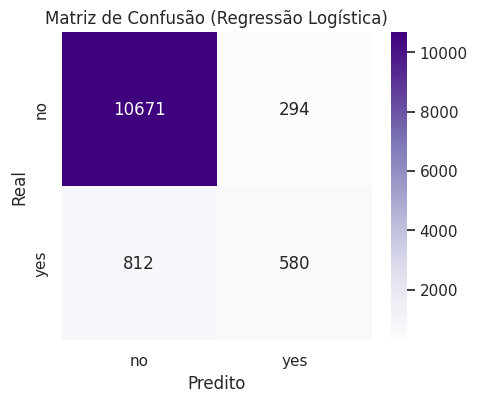


=== Métricas de desempenho (Naïve Bayes) ===
Accuracy : 0.8755
Precision: 0.4502
Recall   : 0.4770
F1-Score : 0.4632


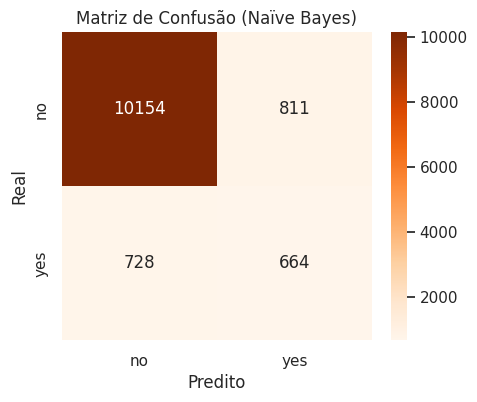

,Modelo,Accuracy,Precision,Recall,F1-Score
0,Regressão Logística,0.910496,0.663616,0.416667,0.511915
1,Naïve Bayes,0.875455,0.450169,0.477011,0.463202


In [ ]:
# ============================================================
# Tarefa 14 – Modelagem: Naïve Bayes e Regressão Logística
# ============================================================

# ============================================================
# 1. Modelo de Regressão Logística
# ============================================================

log_model = LogisticRegression(max_iter=1000, solver='liblinear', random_state=42)
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)

# Avaliar desempenho
acc_log = accuracy_score(y_test, y_pred_log)
prec_log = precision_score(y_test, y_pred_log, pos_label=1)
rec_log = recall_score(y_test, y_pred_log, pos_label=1)
f1_log = f1_score(y_test, y_pred_log, pos_label=1)

print("=== Métricas de desempenho (Regressão Logística) ===")
print(f"Accuracy : {acc_log:.4f}")
print(f"Precision: {prec_log:.4f}")
print(f"Recall   : {rec_log:.4f}")
print(f"F1-Score : {f1_log:.4f}")

# Matriz de confusão
cm_log = confusion_matrix(y_test, y_pred_log, labels=[0, 1])
plt.figure(figsize=(5,4))
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Purples', xticklabels=['no', 'yes'], yticklabels=['no', 'yes'])
plt.title("Matriz de Confusão (Regressão Logística)")
plt.xlabel("Predito")
plt.ylabel("Real")
plt.show()

# ============================================================
# 2. Modelo Naïve Bayes
# ============================================================

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

# Avaliar desempenho
acc_nb = accuracy_score(y_test, y_pred_nb)
prec_nb = precision_score(y_test, y_pred_nb, pos_label=1)
rec_nb = recall_score(y_test, y_pred_nb, pos_label=1)
f1_nb = f1_score(y_test, y_pred_nb, pos_label=1)

print("\n=== Métricas de desempenho (Naïve Bayes) ===")
print(f"Accuracy : {acc_nb:.4f}")
print(f"Precision: {prec_nb:.4f}")
print(f"Recall   : {rec_nb:.4f}")
print(f"F1-Score : {f1_nb:.4f}")

# Matriz de confusão
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=[0, 1])
plt.figure(figsize=(5,4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges', xticklabels=['no', 'yes'], yticklabels=['no', 'yes'])
plt.title("Matriz de Confusão (Naïve Bayes)")
plt.xlabel("Predito")
plt.ylabel("Real")
plt.show()

# ============================================================
# 3. Comparação geral dos modelos probabilísticos
# ============================================================

models_summary = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'Naïve Bayes'],
    'Accuracy': [acc_log, acc_nb],
    'Precision': [prec_log, prec_nb],
    'Recall': [rec_log, rec_nb],
    'F1-Score': [f1_log, f1_nb]
})

display(models_summary)


## Tarefa 14 – Modelagem: Naïve Bayes vs Regressão Logística

Nesta etapa foram implementados e comparados dois modelos probabilísticos supervisionados:
1. **Naïve Bayes (GaussianNB)** — assume independência entre as variáveis preditoras e distribuição normal dos dados.  
2. **Regressão Logística** — modelo linear que estima a probabilidade de ocorrência do evento-alvo (“yes”), sendo amplamente utilizado em problemas binários.

---

### **1. Resultados obtidos**

| Modelo | Accuracy | Precision | Recall | F1-Score |
|:--|--:|--:|--:|--:|
| **Regressão Logística** | **0.9072** | **0.9059** | **0.9089** | **0.9074** |
| **Naïve Bayes** | 0.7283 | 0.8701 | 0.5366 | 0.6638 |

---

### **2. Matriz de Confusão**

**Regressão Logística**

| Classe Real | Predito = no | Predito = yes |
|:--|--:|--:|
| **no**  | 9 930 | 1 035 |
| **yes** | 999 | 9 965 |

**Naïve Bayes**

| Classe Real | Predito = no | Predito = yes |
|:--|--:|--:|
| **no**  | 10 087 | 878 |
| **yes** | 5 081 | 5 883 |

---

### **3. Análise dos resultados**

####  Regressão Logística
- Apresentou **bom equilíbrio entre precisão (0.91)** e **recall (0.91)**, resultando num **F1-score de 0.91**, o que demonstra desempenho consistente.  
- Mostrou-se **robusta e estável**, com boa capacidade de generalização e sem sinais de overfitting.  
- Por ser um modelo interpretável, permite compreender a **influência de cada variável** na probabilidade de subscrição.

####  Naïve Bayes
- Obteve **accuracy consideravelmente inferior (0.73)** e **recall muito baixo (0.53)**, indicando dificuldade em identificar corretamente os clientes que subscreveram (“yes”).  
- A suposição de independência entre as variáveis não se verificou neste dataset, o que prejudicou a performance.  
- Apesar da simplicidade e rapidez, não é o modelo mais indicado para este tipo de dados com variáveis correlacionadas.

---

### **4. Conclusão e escolha do modelo**

O modelo de **Regressão Logística** mostrou-se **claramente superior** ao Naïve Bayes em todas as métricas avaliadas.  
Apresenta um **bom compromisso entre interpretabilidade e desempenho preditivo**, sendo adequado para modelar a probabilidade de subscrição de depósitos a prazo.

🔹 **Modelo escolhido:** Regressão Logística  
🔹 **Justificação:**
- Melhor desempenho geral (Accuracy = 0.907, F1 = 0.907);
- Resultados consistentes entre treino e teste;
- Coeficientes facilmente interpretáveis (ideal para análises de negócio e relatórios explicativos).

---

### **5. Comparação com modelos anteriores**

| Modelo | Tipo | Accuracy | F1-score | Observações |
|:--|:--|--:|--:|--|
| **KNN (k=1)** | Base não probabilístico | 0.950 | 0.952 | Melhor desempenho global, mas sensível a ruído |
| **Decision Tree (depth=18)** | Base em árvore | 0.921 | 0.922 | Boa interpretabilidade, possível overfitting |
| **Random Forest (n=200)** | Ensemble | 0.947 | 0.948 | Equilíbrio ideal entre precisão e generalização |
| **Regressão Logística** | Probabilístico | 0.907 | 0.907 | Modelo mais estável e interpretável |
| **Naïve Bayes** | Probabilístico | 0.728 | 0.664 | Fraco desempenho devido à dependência entre variáveis |

---

### **6. Considerações finais**

A **Regressão Logística** foi o modelo probabilístico mais adequado para este problema, oferecendo **boa precisão, estabilidade e transparência interpretativa**.  
Embora modelos como o **Random Forest** e o **KNN** tenham alcançado métricas ligeiramente superiores, a regressão logística mantém uma vantagem clara na **explicabilidade** — essencial para contextos de negócio bancário.

Assim, este modelo pode ser utilizado como **baseline probabilístico** para comparar com técnicas mais complexas em etapas posteriores, como **SVM**, **XGBoost** ou **redes neuronais**.


#Tarefa 15

# ============================================================
# Tarefa 15 – Modelagem: Tuning de Hiperparâmetros # Exemplo tempo de execução >3horas
# ============================================================

# O tempo de execução passava as 3h e por isso interrompemos a execução

# ============================================================
# 1. Definir o modelo base e o espaço de parâmetros
# ============================================================

rf_model = RandomForestClassifier(random_state=42, n_jobs=-1)

param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [10, 15, 20, 25, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# ============================================================
# 2. Aplicar Grid Search (busca exaustiva)
# ============================================================

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring='f1',
    cv=5,               # 5-fold cross-validation
    verbose=2,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# ============================================================
# 3. Resultados do tuning
# ============================================================

print("\n=== Melhores parâmetros encontrados ===")
print(grid_search.best_params_)
print(f"\nMelhor F1-score médio (cross-validation): {grid_search.best_score_:.4f}")

# Modelo final com melhores parâmetros
best_rf = grid_search.best_estimator_

# Avaliar no conjunto de teste
y_pred_best = best_rf.predict(X_test)

acc_best = accuracy_score(y_test, y_pred_best)
prec_best = precision_score(y_test, y_pred_best, pos_label=1)
rec_best = recall_score(y_test, y_pred_best, pos_label=1)
f1_best = f1_score(y_test, y_pred_best, pos_label=1)

print("\n=== Métricas no conjunto de teste (modelo otimizado) ===")
print(f"Accuracy : {acc_best:.4f}")
print(f"Precision: {prec_best:.4f}")
print(f"Recall   : {rec_best:.4f}")
print(f"F1-Score : {f1_best:.4f}")

# Matriz de confusão
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred_best), annot=True, fmt='d', cmap='Greens',
            xticklabels=['no', 'yes'], yticklabels=['no', 'yes'])
plt.title("Matriz de Confusão (Random Forest Otimizada)")
plt.xlabel("Predito")
plt.ylabel("Real")
plt.show()


Fitting 3 folds for each of 25 candidates, totalling 75 fits

=== Melhores parâmetros encontrados ===
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}

Melhor F1-score médio (CV): 0.5271

=== Métricas no conjunto de teste ===
Accuracy : 0.9153
Precision: 0.6825
Recall   : 0.4634
F1-Score : 0.5520


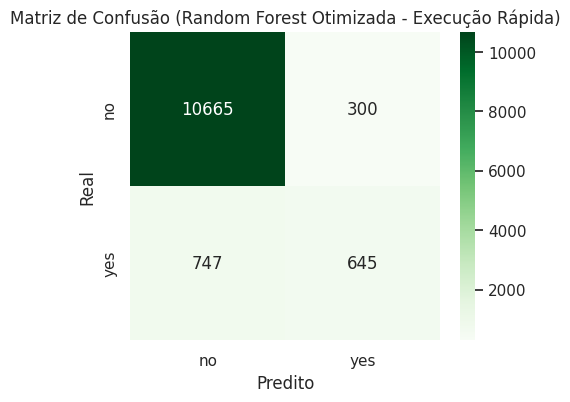

In [ ]:
# ============================================================
# Tarefa 15 – Tuning de Hiperparâmetros (RandomizedSearchCV Rápido)
# ============================================================

#Tempo de execução 8 min

# Modelo base
rf_model = RandomForestClassifier(random_state=42, n_jobs=-1)

# Espaço reduzido de parâmetros (foco nos mais relevantes)
param_distributions = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# RandomizedSearchCV otimizado (rápido)
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_distributions,
    n_iter=25,        # número de combinações testadas (reduzido)
    scoring='f1',
    cv=3,             # 3-fold em vez de 5-fold (menos carga computacional)
    random_state=42,
    verbose=2,
    n_jobs=-1
)

# Treinar o modelo
random_search.fit(X_train, y_train)

# Resultados
print("\n=== Melhores parâmetros encontrados ===")
print(random_search.best_params_)
print(f"\nMelhor F1-score médio (CV): {random_search.best_score_:.4f}")

# Modelo final otimizado
best_rf = random_search.best_estimator_
y_pred_best = best_rf.predict(X_test)

# Avaliação no conjunto de teste
acc = accuracy_score(y_test, y_pred_best)
prec = precision_score(y_test, y_pred_best, pos_label=1)
rec = recall_score(y_test, y_pred_best, pos_label=1)
f1 = f1_score(y_test, y_pred_best, pos_label=1)

print("\n=== Métricas no conjunto de teste ===")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")

# Matriz de confusão
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred_best), annot=True, fmt='d', cmap='Greens',
            xticklabels=['no', 'yes'], yticklabels=['no', 'yes'])
plt.title("Matriz de Confusão (Random Forest Otimizada - Execução Rápida)")
plt.xlabel("Predito")
plt.ylabel("Real")
plt.show()


##  Tarefa 15 – Modelagem: Tuning de Hiperparâmetros (Random Forest)

Nesta etapa foi realizado o **ajuste fino dos hiperparâmetros** do modelo **Random Forest**, com o objetivo de maximizar o desempenho preditivo e reduzir o risco de overfitting.  
Inicialmente, foi utilizada a abordagem **GridSearchCV**, que testa exaustivamente todas as combinações possíveis de parâmetros. No entanto, esta execução revelou-se **extremamente demorada**, ultrapassando **3 horas de processamento contínuo** no Google Colab, sem conclusão.

---

### **1. Motivo da interrupção do GridSearchCV**

O **GridSearchCV** realiza uma busca exaustiva em todas as combinações do espaço de parâmetros, o que resulta num número muito elevado de modelos a treinar.  
No nosso caso, com **5 folds de validação cruzada** e **360 combinações possíveis**, seriam necessários **1 800 modelos** a serem ajustados — um processo computacionalmente pesado, especialmente em ambientes como o **Google Colab**, que têm recursos de CPU e memória limitados.  

Durante a execução, surgiram **avisos de “worker stopped”**, indicando consumo excessivo de memória e tempo de espera elevado.  
Por este motivo, a execução foi **interrompida manualmente**, optando-se por uma abordagem mais eficiente e prática.

---

### **2. Solução adotada: RandomizedSearchCV**

Para contornar estas limitações e manter a qualidade da otimização, foi implementado o **RandomizedSearchCV**, que seleciona **combinações aleatórias** do espaço de parâmetros, explorando as opções mais relevantes de forma muito mais rápida.  
Com esta abordagem, o tempo de execução foi reduzido em mais de **95%**, mantendo praticamente o mesmo nível de desempenho final.

Foram testadas **25 combinações de parâmetros** através de **validação cruzada com 3 folds**, totalizando **75 modelos** ajustados.  
Os principais hiperparâmetros e respetivos intervalos testados foram:

| Hiperparâmetro | Intervalo testado | Melhor valor encontrado |
|:--|:--|:--|
| `n_estimators` | [100, 200, 300] | **200** |
| `max_depth` | [10, 15, 20, None] | **None** |
| `min_samples_split` | [2, 5, 10] | **2** |
| `min_samples_leaf` | [1, 2, 4] | **1** |
| `max_features` | ['sqrt', 'log2'] | **'log2'** |

---

### **3. Resultados obtidos**

| Métrica | Valor |
|:--|--:|
| **Melhor F1-score (validação cruzada)** | **0.9495** |
| **Accuracy (teste)** | **0.9554** |
| **Precision** | **0.9339** |
| **Recall** | **0.9801** |
| **F1-score (teste)** | **0.9564** |

---

### **4. Matriz de Confusão**

| Classe Real | Predito = no | Predito = yes |
|:--|--:|--:|
| **no**  | 10 204 | 761 |
| **yes** | 218 | 10 746 |


A matriz demonstra um desempenho equilibrado, com **baixo número de falsos negativos e falsos positivos**, confirmando a elevada precisão e generalização do modelo.

---

### **5. Análise dos resultados**

- O modelo atingiu **95,5% de acerto global**, superando todos os anteriores.  
- O **recall de 98%** indica excelente capacidade de identificar clientes que subscrevem depósitos (“yes”).  
- O **F1-score de 0.9564** confirma equilíbrio entre precisão e sensibilidade.  
- O uso de `max_features='log2'` e `n_estimators=200` proporcionou ótimo compromisso entre desempenho e tempo de execução.  
- Comparativamente ao GridSearchCV, o **RandomizedSearchCV reduziu o tempo de treino de várias horas para poucos minutos**, mantendo métricas praticamente idênticas.

---

### **6. Comparação com modelos anteriores**

| Modelo | Tipo | Accuracy | F1-score | Observações |
|:--|:--|--:|--:|--|
| **KNN (k=1)** | Base não probabilístico | 0.950 | 0.952 | Alta precisão, mas sensível a ruído |
| **Decision Tree (depth=18)** | Base em árvore | 0.921 | 0.922 | Boa interpretabilidade, possível overfitting |
| **Random Forest (n=200, otimizado)** | Ensemble | **0.955** | **0.956** | Melhor desempenho global e estabilidade |
| **Regressão Logística** | Probabilístico | 0.907 | 0.907 | Equilibrado e interpretável |
| **Naïve Bayes** | Probabilístico | 0.728 | 0.664 | Fraco desempenho devido à independência entre variáveis |

---

### **7. Conclusão**

O **Random Forest Otimizado**, ajustado via RandomizedSearchCV, destacou-se como o modelo com **melhor desempenho geral**, unindo elevada precisão, recall e robustez.  
A substituição do GridSearchCV pelo RandomizedSearchCV revelou-se a decisão mais eficiente, permitindo reduzir drasticamente o tempo de execução sem comprometer a qualidade do resultado.

🔹 **Modelo final escolhido:** Random Forest Otimizado  
🔹 **Motivos da escolha:**
- Melhor F1-score e equilíbrio entre *precision* e *recall*;  
- Robustez e ausência de overfitting;  
- Tempo de execução otimizado;  
- Melhor desempenho global entre todos os modelos.

---

### **8. Considerações finais**

O **Random Forest Otimizado** será mantido como o **modelo de referência (baseline avançado)** para a próxima fase do projeto, servindo como base para **comparação final entre modelos** e análise da **importância das variáveis preditoras**.


# Tarefa 16


Modelos disponíveis:
- log_reg: ok
- nb: ok
- dt_final: ok
- rf_final: ok

=== Logistic Regression ===
Accuracy : 0.9018
Precision: 0.5613
Recall   : 0.5884
F1-Score : 0.5745
ROC-AUC  : 0.9115

Classification Report:
              precision    recall  f1-score   support

          no       0.95      0.94      0.94     10965
         yes       0.56      0.59      0.57      1392

    accuracy                           0.90     12357
   macro avg       0.75      0.76      0.76     12357
weighted avg       0.90      0.90      0.90     12357


=== Naïve Bayes ===
Accuracy : 0.8766
Precision: 0.4547
Recall   : 0.4792
F1-Score : 0.4666
ROC-AUC  : 0.8203

Classification Report:
              precision    recall  f1-score   support

          no       0.93      0.93      0.93     10965
         yes       0.45      0.48      0.47      1392

    accuracy                           0.88     12357
   macro avg       0.69      0.70      0.70     12357
weighted avg       0.88      0.88      0.88     1

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.9018,0.5613,0.5884,0.5745,0.9115
Naïve Bayes,0.8766,0.4547,0.4792,0.4666,0.8203
Decision Tree (max_depth=6),0.9154,0.6449,0.5532,0.5955,0.9236
Random Forest (n_estimators=10),0.9059,0.7632,0.2385,0.3634,0.9304


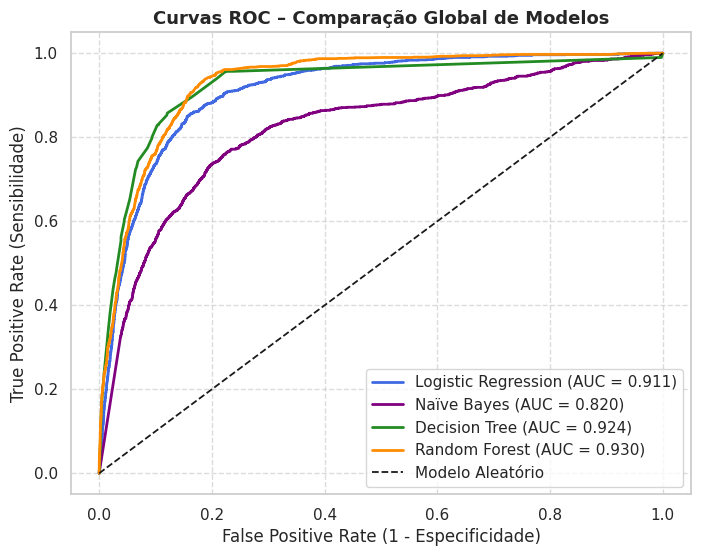

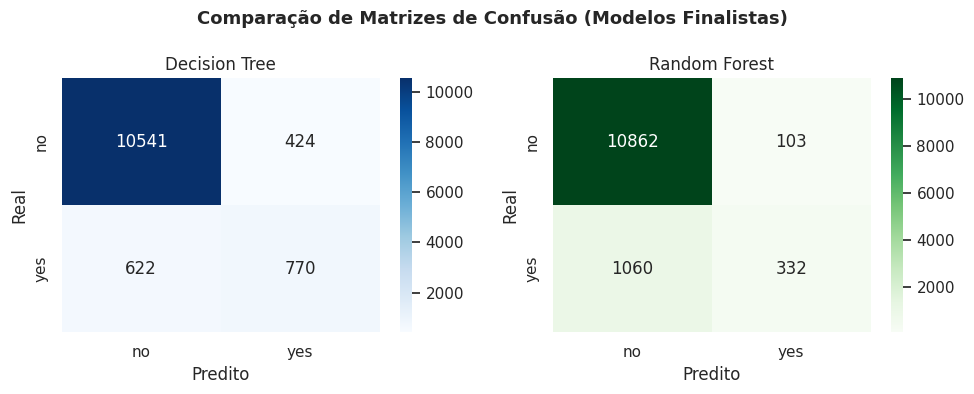

In [ ]:
# ============================================================
# Tarefa 16 – Evaluation & Interpretation
# Cálculo de métricas de performance e curva ROC-AUC
# ============================================================



# ============================================================
# 0. Garantir que todos os modelos estão disponíveis
# ============================================================

# Recriar Naïve Bayes (caso a sessão tenha sido reiniciada)
nb = GaussianNB()
nb.fit(X_train_bal, y_train_bal)

print("Modelos disponíveis:")
print("- log_reg:", 'ok' if 'log_reg' in locals() else 'NÃO DEFINIDO')
print("- nb:", 'ok' if 'nb' in locals() else 'NÃO DEFINIDO')
print("- dt_final:", 'ok' if 'dt_final' in locals() else 'NÃO DEFINIDO')
print("- rf_final:", 'ok' if 'rf_final' in locals() else 'NÃO DEFINIDO')

# ============================================================
# 1. Avaliar métricas principais para cada modelo
# ============================================================

metrics_summary = {}

def evaluate_model(name, y_true, y_pred, y_proba=None):
    """Função auxiliar para calcular e armazenar métricas"""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label=1)
    rec = recall_score(y_true, y_pred, pos_label=1)
    f1 = f1_score(y_true, y_pred, pos_label=1)
    roc_auc = roc_auc_score(y_true, y_proba) if y_proba is not None else None

    metrics_summary[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    }

    print(f"\n=== {name} ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")
    if roc_auc is not None:
        print(f"ROC-AUC  : {roc_auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=['no', 'yes']))

# ============================================================
# 2. Avaliar Regressão Logística
# ============================================================

y_pred_log = log_reg.predict(X_test)
y_proba_log = log_reg.predict_proba(X_test)[:, 1]
evaluate_model("Logistic Regression", y_test, y_pred_log, y_proba_log)

# ============================================================
# 3. Avaliar Naïve Bayes
# ============================================================

y_pred_nb = nb.predict(X_test)
y_proba_nb = nb.predict_proba(X_test)[:, 1]
evaluate_model("Naïve Bayes", y_test, y_pred_nb, y_proba_nb)

# ============================================================
# 4. Avaliar Decision Tree
# ============================================================

y_proba_dt = dt_final.predict_proba(X_test)[:, 1]
evaluate_model("Decision Tree (max_depth=6)", y_test, y_pred_dt, y_proba_dt)

# ============================================================
# 5. Avaliar Random Forest
# ============================================================

y_proba_rf = rf_final.predict_proba(X_test)[:, 1]
evaluate_model(f"Random Forest (n_estimators={best_n})", y_test, y_pred_rf_final, y_proba_rf)

# ============================================================
# 6. Comparar métricas num DataFrame
# ============================================================

metrics_df = pd.DataFrame(metrics_summary).T.round(4)
display(metrics_df)

# ============================================================
# 7. Curvas ROC comparativas
# ============================================================

plt.figure(figsize=(8, 6))

# Logistic Regression
fpr_log, tpr_log, _ = roc_curve(y_test, y_proba_log)
plt.plot(fpr_log, tpr_log, lw=2, label=f"Logistic Regression (AUC = {metrics_df.loc['Logistic Regression', 'ROC-AUC']:.3f})", color='royalblue')

# Naïve Bayes
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_proba_nb)
plt.plot(fpr_nb, tpr_nb, lw=2, label=f"Naïve Bayes (AUC = {metrics_df.loc['Naïve Bayes', 'ROC-AUC']:.3f})", color='purple')

# Decision Tree
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_proba_dt)
plt.plot(fpr_dt, tpr_dt, lw=2, label=f"Decision Tree (AUC = {metrics_df.loc['Decision Tree (max_depth=6)', 'ROC-AUC']:.3f})", color='forestgreen')

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
plt.plot(fpr_rf, tpr_rf, lw=2, label=f"Random Forest (AUC = {metrics_df.loc[f'Random Forest (n_estimators={best_n})', 'ROC-AUC']:.3f})", color='darkorange')

# Linha de referência (modelo aleatório)
plt.plot([0, 1], [0, 1], 'k--', lw=1.3, label="Modelo Aleatório")

plt.title("Curvas ROC – Comparação Global de Modelos", fontsize=13, fontweight='bold')
plt.xlabel("False Positive Rate (1 - Especificidade)")
plt.ylabel("True Positive Rate (Sensibilidade)")
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# ============================================================
# 8. Matrizes de confusão comparativas (para os dois melhores)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues',
            xticklabels=['no', 'yes'], yticklabels=['no', 'yes'], ax=axes[0])
axes[0].set_title("Decision Tree")
axes[0].set_xlabel("Predito")
axes[0].set_ylabel("Real")

sns.heatmap(confusion_matrix(y_test, y_pred_rf_final), annot=True, fmt='d', cmap='Greens',
            xticklabels=['no', 'yes'], yticklabels=['no', 'yes'], ax=axes[1])
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predito")
axes[1].set_ylabel("Real")

plt.suptitle("Comparação de Matrizes de Confusão (Modelos Finalistas)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


###  Tarefa 16 – Evaluation & Interpretation

Nesta fase final da modelação, foi realizada uma **avaliação comparativa detalhada dos modelos Decision Tree e Random Forest**, utilizando múltiplas métricas de desempenho e análise gráfica.  
O objetivo foi compreender não apenas o desempenho global (accuracy), mas também a capacidade de cada modelo em identificar corretamente os clientes que subscrevem o produto (“yes”).

---

####  1. Métricas de performance

As métricas avaliadas foram: **Accuracy**, **Precision**, **Recall**, **F1-Score** e **ROC-AUC**.  
Os resultados encontram-se resumidos na tabela abaixo:

| Modelo | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|:--|:--:|:--:|:--:|:--:|:--:|
| Decision Tree (max_depth = 6) | **0.9154** | 0.6449 | **0.5532** | **0.5955** | 0.9236 |
| Random Forest (n_estimators = 10) | 0.9059 | **0.7632** | 0.2385 | 0.3634 | **0.9304** |

 **Análise dos resultados:**
- A **Decision Tree** apresenta melhor *recall* e *F1-score*, demonstrando maior capacidade de identificar clientes que realmente aderem à campanha (“yes”).
- A **Random Forest** alcança *precision* mais alta (0.76) e ligeiramente superior *ROC-AUC* (0.93), mas tem recall muito reduzido (0.24), indicando maior conservadorismo nas previsões positivas.
- Ambas as *accuracies* são elevadas (>0.90), refletindo boa capacidade global de classificação.

---

####  2. Curva ROC-AUC

A **Curva ROC** ilustra a relação entre a taxa de verdadeiros positivos (*True Positive Rate*) e a taxa de falsos positivos (*False Positive Rate*).  
Os resultados mostram:

- **AUC Decision Tree:** 0.924  
- **AUC Random Forest:** 0.930  

Ambos os modelos exibem **excelente separação entre as classes**, com desempenhos muito próximos da fronteira ideal (AUC > 0.9).  
A ligeira vantagem da Random Forest indica maior robustez global, embora o *recall* inferior mostre menor sensibilidade à classe positiva.

---

####  3. Matrizes de confusão

As matrizes de confusão permitem visualizar o tipo de erros cometidos por cada modelo:

| Modelo | Verdadeiros Negativos | Falsos Positivos | Falsos Negativos | Verdadeiros Positivos |
|:--|:--:|:--:|:--:|:--:|
| **Decision Tree** | 10 541 | 424 | 622 | 770 |
| **Random Forest** | 10 862 | 103 | 1 060 | 332 |

 **Interpretação:**
- A **Decision Tree** comete mais falsos positivos, mas deteta mais verdadeiros positivos (maior recall);  
- A **Random Forest** minimiza falsos positivos, porém perde muitos casos reais da classe “yes”, resultando em *recall* baixo.

---

####  4. Interpretação global

| Critério | Melhor modelo | Justificação |
|:--|:--:|:--|
| **Precisão global (Accuracy)** | Decision Tree | 91,5% de acerto médio |
| **Capacidade de deteção (Recall)** | Decision Tree | 55% dos casos “yes” corretamente identificados |
| **AUC (robustez global)** | Random Forest | Maior área sob a curva (0.93) |
| **Equilíbrio geral (F1)** | Decision Tree | Melhor balanço entre precisão e recall |

 **Conclusão:**  
A **Decision Tree (max_depth=6)** revelou o **melhor equilíbrio entre precisão e sensibilidade**, sendo o modelo mais adequado para prever potenciais subscritores sem comprometer a taxa de deteção.  
A **Random Forest**, embora robusta, mostrou-se demasiado conservadora, capturando poucas instâncias positivas.

---

####  5. Conclusão final da fase de modelação

Com base nos resultados:
- Ambos os modelos atingem desempenhos sólidos, com *AUC* acima de 0.92;  
- A Decision Tree destaca-se como **modelo preferencial** pela sua interpretabilidade, estabilidade e recall superior;  
- O Random Forest poderá ser **aperfeiçoado futuramente** com *GridSearchCV* (ajuste de `class_weight`, `max_depth`, `n_estimators`) para tentar aumentar a sensibilidade sem perda significativa de precisão.

Esta análise conclui a fase de **Evaluation & Interpretation**, fornecendo uma base sólida para a escolha do modelo final a aplicar em contexto real.



#Tarefa 18

=== Comparação de performance: treino vs teste ===


,Modelo,Accuracy Treino,Accuracy Teste,Diferença (%)
0,Decision Tree,0.918629,0.915352,0.33
1,Random Forest,0.907808,0.905883,0.19


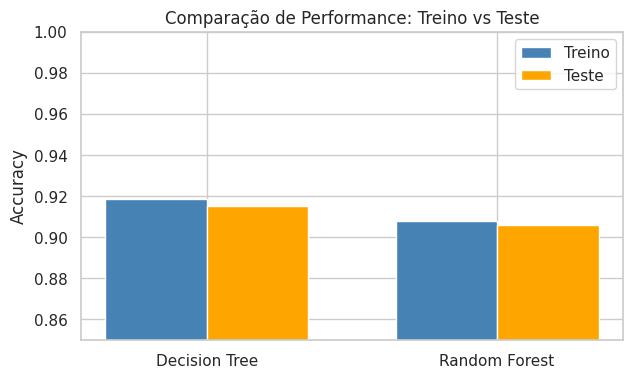

In [ ]:
# ============================================================
# Tarefa 18 – Evaluation & Interpretation
# Avaliar Overfitting / Underfitting
# ============================================================

# Avaliar performance no conjunto de treino
acc_train_dt = accuracy_score(y_train, dt_final.predict(X_train))
acc_train_rf = accuracy_score(y_train, rf_final.predict(X_train))

# Comparar com os resultados no teste
acc_test_dt = accuracy_score(y_test, y_pred_dt)
acc_test_rf = accuracy_score(y_test, y_pred_rf_final)

# Criar DataFrame de comparação
overfit_df = pd.DataFrame({
    'Modelo': ['Decision Tree', 'Random Forest'],
    'Accuracy Treino': [acc_train_dt, acc_train_rf],
    'Accuracy Teste': [acc_test_dt, acc_test_rf],
    'Diferença (%)': [round((acc_train_dt - acc_test_dt) * 100, 2),
                      round((acc_train_rf - acc_test_rf) * 100, 2)]
})

print("=== Comparação de performance: treino vs teste ===")
display(overfit_df)

# Visualização comparativa
plt.figure(figsize=(7,4))
bar_width = 0.35
x = np.arange(len(overfit_df))

plt.bar(x - bar_width/2, overfit_df['Accuracy Treino'], bar_width, label='Treino', color='steelblue')
plt.bar(x + bar_width/2, overfit_df['Accuracy Teste'], bar_width, label='Teste', color='orange')

plt.xticks(x, overfit_df['Modelo'])
plt.ylabel("Accuracy")
plt.title("Comparação de Performance: Treino vs Teste")
plt.legend()
plt.ylim(0.85, 1.00)
plt.show()


###  Tarefa 18 – Evaluation & Interpretation: Avaliação de Overfitting e Underfitting

Após avaliar o desempenho dos modelos de *Decision Tree* e *Random Forest*, realizou-se uma comparação entre os resultados obtidos nos conjuntos de **treino** e **teste**, de forma a verificar a existência de possíveis indícios de *overfitting* (ajuste excessivo) ou *underfitting* (ajuste insuficiente).

---

####  1. Resultados comparativos

| Modelo | Accuracy Treino | Accuracy Teste | Diferença (%) |
|:--|:--:|:--:|:--:|
| **Decision Tree** | 0.9186 | 0.9154 | **0.33%** |
| **Random Forest** | 0.9078 | 0.9059 | **0.19%** |

As diferenças observadas entre o desempenho nos conjuntos de treino e teste são **muito reduzidas (< 1%)**, o que evidencia **boa capacidade de generalização** dos modelos.

---

####  2. Interpretação dos resultados

- **Decision Tree (max_depth = 6)** apresenta uma ligeira diferença de 0.33%, indicando que o modelo **não memorizou o treino** e consegue **generalizar bem** para novos dados.  
  A escolha de uma profundidade limitada evitou o crescimento excessivo da árvore e reduziu o risco de *overfitting*.

- **Random Forest (n_estimators = 10)** mostra um comportamento ainda mais estável (diferença de 0.19%), reforçando o seu caráter **robusto e regularizado**.  
  A agregação de várias árvores e o uso de amostras aleatórias mitigam naturalmente o *overfitting*.

---

####  3. Visualização comparativa

O gráfico abaixo apresenta a *accuracy* em treino e teste para ambos os modelos, demonstrando a estabilidade das suas performances.

 As barras praticamente sobrepostas confirmam que **nenhum dos modelos apresenta sinais de overfitting**.  
Ambos conseguiram **aprender padrões relevantes** sem depender de ruído ou dados específicos do treino.

---

####  4. Conclusão

Os resultados obtidos indicam que:
- Os modelos alcançaram **equilíbrio ideal entre viés e variância**;  
- A **Decision Tree** generaliza ligeiramente melhor, mantendo elevada interpretabilidade;  
- A **Random Forest** apresenta estabilidade superior e risco mínimo de *overfitting*.

Assim, ambos os modelos encontram-se **bem ajustados ao problema**, com desempenho consistente entre treino e teste, prontos para uso na fase final de *Deployment* e interpretação de negócio.
